In [63]:
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

        #DOSYALAR
#CSAT_Survey_Data.csv

#Customer_Age_Data.csv
#Customer_MRR_Data.csv
#Customer_Revenue_Data.csv
#Help_Ticket_Data.csv
#Newsletter_Interaction_Data.csv
#Product_Bug_Task_Data.csv
#RegionAndVertical_Data.csv
#StatusAndLevel_Data.csv

/kaggle/input/datas/Customer_Age_Data.csv
/kaggle/input/datas/Help_Ticket_Data.csv
/kaggle/input/datas/Customer_MRR_Data.csv
/kaggle/input/datas/StatusAndLevel_Data.csv
/kaggle/input/datas/Newsletter_Interaction_Data.csv
/kaggle/input/datas/RegionAndVertical_Data.csv
/kaggle/input/datas/Product_Bug_Task_Data.csv
/kaggle/input/datas/CSAT_Survey_Data.csv
/kaggle/input/datas/Customer_Revenue_Data.csv


# ***VERİLERİN GİRDİSİ VE VERİ TEMİZLEME*** 

In [64]:
survey_df = pd.read_csv("/kaggle/input/datas/CSAT_Survey_Data.csv")

age_df = pd.read_csv("/kaggle/input/datas/Customer_Age_Data.csv")
mrr_df = pd.read_csv("/kaggle/input/datas/Customer_MRR_Data.csv")
revenue_df = pd.read_csv("/kaggle/input/datas/Customer_Revenue_Data.csv")
helpTicket_df = pd.read_csv("/kaggle/input/datas/Help_Ticket_Data.csv")
newsLetterInteraction_df = pd.read_csv("/kaggle/input/datas/Newsletter_Interaction_Data.csv")
productBug_df = pd.read_csv("/kaggle/input/datas/Product_Bug_Task_Data.csv")
regionAndVertical_df = pd.read_csv("/kaggle/input/datas/RegionAndVertical_Data.csv")
statusAndLevel_df = pd.read_csv("/kaggle/input/datas/StatusAndLevel_Data.csv")

#Verileri pandas ile kolayca işleyebilceğimiz dataframe lere aktarıyoruz.

# Survey Data nın incelenmesi ve temizlenmesi

In [65]:
#Müşteri anketi tablosunun nasıl olduğunu inceleyelim.
survey_df.head(10)

,Customer ID,Year,Quarter,Survey Date,Response Date,How likely are you to recommend insider to a friend or colleague,How would you rate the value you gain from our company,How frequently are you using our platform,Please rate the overall quality of our products,Please rate the usability of the panel,Please rate your understanding of our reporting capabilities in the panel
0,CRM-1516050,2022,3,2022-07-01,2022-08-26,10,5,Once a Month,5,5.0,I need someone from Insider team to provide me...
1,CRM-1516050,2022,3,2022-07-01,2022-09-27,10,5,Once a Month,5,5.0,I don't use it often
2,CRM-1470950,2022,1,2022-01-01,2022-03-25,4,3,Once a Day,2,3.0,I need someone from Insider team to provide me...
3,CRM-1470950,2022,3,2022-07-01,2022-09-30,6,3,Once a Week,4,4.0,I tried but could not find everything I need
4,CRM-1470950,2022,2,2022-04-01,2022-06-23,10,5,Once a Day,4,3.0,I need someone from Insider team to provide me...
5,CRM-1470950,2022,1,2022-01-01,2022-03-28,7,4,Once a Day,4,4.0,I need someone from Insider team to provide me...
6,CRM-1470950,2022,1,2022-01-01,2022-03-28,9,5,Once a Week,5,5.0,I am able to report everything easily
7,CRM-1470950,2022,3,2022-07-01,2022-08-05,8,4,Once a Week,4,4.0,I tried but could not find everything I need
8,CRM-1526100,2022,2,2022-04-01,2022-06-06,10,5,Once a Month,5,5.0,I need someone from Insider team to provide me...
9,CRM-1526100,2022,3,2022-07-01,2022-09-30,9,4,Once a Week,4,4.0,I am able to report everything easily


In [66]:
#Dataframe i daha iyi analiz edebilmek için temizleyelim ve tabiki bunu bir kopya üzerinde yapalım.
copy_survey_df = survey_df.copy()

#Öncelikli olarak gereksiz gördüğüm year, Survey Date, Response Date kolonlarını kaldıralım.
copy_survey_df = copy_survey_df.drop('Year', axis=1).drop('Survey Date', axis=1).drop('Response Date', axis=1)

#Aynı ID lere sahip satırları bir araya getirelim ki daha geniş bir perspektiften verileri inceleyelim aynı zamanda gereksiz satırlardan kurtulmuş oluyoruz.
quarter_seperated_df = copy_survey_df.pivot_table(index='Customer ID', columns='Quarter', aggfunc='first').dropna()

quarter_seperated_df.head(10)

#Verilerin nasıl gruplandığını aşağıdaki tablo ile rahat anlayabiliyoruz. Ancak işlem yapması o kadar kolay olmayacağı için işlemlerimize başka bir Data Frame ile devam edeceğiz.


How frequently are you using our platform                \
Quarter                                             1             2   
Customer ID                                                           
CRM-1030400                               Once a Week  Once a Month   
CRM-1079000                                Once a Day    Once a Day   
CRM-1091300                                Once a Day  Once a Month   
CRM-1149100                                Once a Day   Once a Week   
CRM-1194100                               Once a Week   Once a Week   
CRM-1199150                                Once a Day   Once a Week   
CRM-1205200                               Once a Week   Once a Week   
CRM-1242200                                Once a Day   Once a Week   
CRM-1290050                                Once a Day    Once a Day   
CRM-1301500                                Once a Day    Once a Day   

                           \
Quarter                 3   
Customer ID                 
CRM-1030400   Once a Week   
CRM-1079000    Once a Day   
CRM-1091300    Once a Day   
CRM-1149100    Once a Day   
CRM-1194100   Once a Week   
CRM-1199150  Once a Month   
CRM-1205200  Once a Month   
CRM-1242200   Once a Week   
CRM-1290050    Once a Day   
CRM-1301500    Once a Day   

            How likely are you to recommend insider to a friend or colleague   \
Quarter                                                                     1   
Customer ID                                                                     
CRM-1030400                                               10.0                  
CRM-1079000                                                8.0                  
CRM-1091300                                                9.0                  
CRM-1149100                                                8.0                  
CRM-1194100                                               10.0                  
CRM-1199150                                                6.0                  
CRM-1205200                                                8.0                  
CRM-1242200                                               10.0                  
CRM-1290050                                                8.0                  
CRM-1301500                                               10.0                  

                         \
Quarter         2     3   
Customer ID               
CRM-1030400   8.0   9.0   
CRM-1079000  10.0  10.0   
CRM-1091300   9.0   9.0   
CRM-1149100   8.0   8.0   
CRM-1194100  10.0  10.0   
CRM-1199150  10.0   7.0   
CRM-1205200   8.0   8.0   
CRM-1242200  10.0  10.0   
CRM-1290050   8.0   8.0   
CRM-1301500   9.0   9.0   

            How would you rate the value you gain from our company            \
Quarter                                                          1    2    3   
Customer ID                                                                    
CRM-1030400                                                5.0      5.0  4.0   
CRM-1079000                                                4.0      5.0  5.0   
CRM-1091300                                                5.0      4.0  5.0   
CRM-1149100                                                4.0      4.0  4.0   
CRM-1194100                                                5.0      5.0  5.0   
CRM-1199150                                                4.0      5.0  4.0   
CRM-1205200                                                4.0      4.0  4.0   
CRM-1242200                                                5.0      5.0  5.0   
CRM-1290050                                                4.0      5.0  4.0   
CRM-1301500                                                4.0      5.0  5.0   

            Please rate the overall quality of our products            \
Quarter                                                   1    2    3   
Customer ID                                                             
CRM-1030400                                 

In [67]:
# İşlem yapacağımız dataframe 
df = survey_df.copy()

df = df.drop('Survey Date', axis=1)

how_frequent_mapping = {
    "Once a Month": 1,
    "Once a Week": 4,
    "Once a Day": 30
}

df["How frequently are you using our platform"] = df["How frequently are you using our platform"].map(how_frequent_mapping)
df = df.assign(**{"How frequently are you using our platform": df["How frequently are you using our platform"].fillna(0)})
df_grup = df.groupby("Customer ID").agg(
{
    "How likely are you to recommend insider to a friend or colleague ": "mean",
    "How would you rate the value you gain from our company": "mean",
    "How frequently are you using our platform": "max",
    "Please rate the overall quality of our products": "mean",
    "Response Date": "max"
}).reset_index()

df_grup.tail(100)

,Customer ID,How likely are you to recommend insider to a friend or colleague,How would you rate the value you gain from our company,How frequently are you using our platform,Please rate the overall quality of our products,Response Date
540,CRM-530450,9.000000,4.0,30.0,4.000000,2022-08-30
541,CRM-532950,10.000000,5.0,30.0,5.000000,2022-09-13
542,CRM-547450,9.000000,4.0,4.0,4.000000,2022-06-17
543,CRM-547500,8.000000,4.0,30.0,4.000000,2022-08-29
544,CRM-547850,10.000000,5.0,1.0,5.000000,2022-09-15
...,...,...,...,...,...,...
635,CRM-960300,9.600000,4.8,4.0,4.600000,2022-09-23
636,CRM-983600,8.750000,4.5,30.0,4.500000,2022-09-01
637,CRM-993250,8.500000,5.0,30.0,3.500000,2022-09-23
638,CRM-998800,8.333333,4.0,30.0,3.666667,2022-07-05


In [68]:
help_response_mapping = {
    "I need someone from Insider team to provide me the report from the panel": 2,
    "I tried but could not find everything I need": 3,
    "I am able to report everything easily": 4,
    "I don't use it often": 1
}
df["Please rate your understanding of our reporting capabilities in the panel"] = df["Please rate your understanding of our reporting capabilities in the panel"].map(help_response_mapping)
df["Please rate your understanding of our reporting capabilities in the panel"] = df["Please rate your understanding of our reporting capabilities in the panel"].fillna(0)
df.head(10)

,Customer ID,Year,Quarter,Response Date,How likely are you to recommend insider to a friend or colleague,How would you rate the value you gain from our company,How frequently are you using our platform,Please rate the overall quality of our products,Please rate the usability of the panel,Please rate your understanding of our reporting capabilities in the panel
0,CRM-1516050,2022,3,2022-08-26,10,5,1.0,5,5.0,2.0
1,CRM-1516050,2022,3,2022-09-27,10,5,1.0,5,5.0,1.0
2,CRM-1470950,2022,1,2022-03-25,4,3,30.0,2,3.0,2.0
3,CRM-1470950,2022,3,2022-09-30,6,3,4.0,4,4.0,3.0
4,CRM-1470950,2022,2,2022-06-23,10,5,30.0,4,3.0,2.0
5,CRM-1470950,2022,1,2022-03-28,7,4,30.0,4,4.0,2.0
6,CRM-1470950,2022,1,2022-03-28,9,5,4.0,5,5.0,4.0
7,CRM-1470950,2022,3,2022-08-05,8,4,4.0,4,4.0,3.0
8,CRM-1526100,2022,2,2022-06-06,10,5,1.0,5,5.0,2.0
9,CRM-1526100,2022,3,2022-09-30,9,4,4.0,4,4.0,4.0


In [69]:
filtered_df = df[df["Quarter"].isin([1, 2, 3])]

#Column to exclude from mean calculation but keep as numbers
exclude_column = "Please rate your understanding of our reporting capabilities in the panel"

#Convert the excluded column to numeric (force errors='coerce' to handle missing data)
filtered_df[exclude_column] = pd.to_numeric(filtered_df[exclude_column], errors='coerce')

#Identify numeric columns (excluding the one we want to keep as a list)
numeric_cols = [col for col in filtered_df.select_dtypes(include=[np.number]).columns if col != exclude_column]
text_cols = filtered_df.select_dtypes(include=["object"]).columns.tolist()

#Function to merge values correctly
def merge_values(series):
    if series.name in numeric_cols:  # Take mean for numeric columns
        return series.mean()
    elif series.name == exclude_column:  # Keep numbers as a list
        return list(series.dropna())  # Keep all values as a list instead of averaging
    else:  # Concatenate text responses
        return " | ".join(series.dropna().astype(str))

#Group by Customer ID and Quarter with proper merging
grouped_df = filtered_df.groupby(["Customer ID", "Year", "Quarter"]).agg(merge_values).reset_index()

#Sort by Customer ID and Quarter
df_sorted = grouped_df.sort_values(["Customer ID", "Quarter"], ascending=True)

#Show last 20 rows
df_sorted.head(20)

/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,Customer ID,Year,Quarter,Response Date,How likely are you to recommend insider to a friend or colleague,How would you rate the value you gain from our company,How frequently are you using our platform,Please rate the overall quality of our products,Please rate the usability of the panel,Please rate your understanding of our reporting capabilities in the panel
0,CRM-1002400,2022,1,2022-03-01 | 2022-03-21,9.0,4.0,1.0,4.0,NaN,"[2.0, 2.0]"
1,CRM-1002400,2022,2,2022-06-10,8.0,4.0,1.0,4.0,3.0,[2.0]
2,CRM-1002400,2022,3,2022-09-29,10.0,4.0,1.0,3.0,3.0,[2.0]
3,CRM-1006000,2022,1,2022-03-01,10.0,5.0,4.0,5.0,NaN,[0.0]
4,CRM-1019500,2022,1,2022-03-01 | 2022-03-21,8.0,4.0,30.0,4.0,NaN,"[4.0, 4.0]"
5,CRM-1019500,2022,2,2022-05-31 | 2022-06-01,9.0,4.5,30.0,4.5,4.5,"[4.0, 4.0]"
6,CRM-1025800,2022,1,2022-03-21,8.0,4.0,4.0,4.0,4.0,[4.0]
7,CRM-1025800,2022,3,2022-09-27,7.0,4.0,4.0,4.0,4.0,[4.0]
8,CRM-1030300,2022,1,2022-03-01 | 2022-03-21 | 2022-03-18 | 2022-03-21,9.0,3.5,15.5,3.5,5.0,"[4.0, 4.0, 1.0, 1.0]"
9,CRM-1030300,2022,3,2022-08-29 | 2022-08-29,9.0,4.0,4.0,4.0,5.0,"[0.0, 1.0]"


In [70]:
grouped_data = df_sorted.groupby("Customer ID").agg(lambda x: list(x)).reset_index()
grouped_data

,Customer ID,Year,Quarter,Response Date,How likely are you to recommend insider to a friend or colleague,How would you rate the value you gain from our company,How frequently are you using our platform,Please rate the overall quality of our products,Please rate the usability of the panel,Please rate your understanding of our reporting capabilities in the panel
0,CRM-1002400,"[2022, 2022, 2022]","[1, 2, 3]","[2022-03-01 | 2022-03-21, 2022-06-10, 2022-09-29]","[9.0, 8.0, 10.0]","[4.0, 4.0, 4.0]","[1.0, 1.0, 1.0]","[4.0, 4.0, 3.0]","[nan, 3.0, 3.0]","[[2.0, 2.0], [2.0], [2.0]]"
1,CRM-1006000,[2022],[1],[2022-03-01],[10.0],[5.0],[4.0],[5.0],[nan],[[0.0]]
2,CRM-1019500,"[2022, 2022]","[1, 2]","[2022-03-01 | 2022-03-21, 2022-05-31 | 2022-06...","[8.0, 9.0]","[4.0, 4.5]","[30.0, 30.0]","[4.0, 4.5]","[nan, 4.5]","[[4.0, 4.0], [4.0, 4.0]]"
3,CRM-1025800,"[2022, 2022]","[1, 3]","[2022-03-21, 2022-09-27]","[8.0, 7.0]","[4.0, 4.0]","[4.0, 4.0]","[4.0, 4.0]","[4.0, 4.0]","[[4.0], [4.0]]"
4,CRM-1030300,"[2022, 2022]","[1, 3]",[2022-03-01 | 2022-03-21 | 2022-03-18 | 2022-0...,"[9.0, 9.0]","[3.5, 4.0]","[15.5, 4.0]","[3.5, 4.0]","[5.0, 5.0]","[[4.0, 4.0, 1.0, 1.0], [0.0, 1.0]]"
...,...,...,...,...,...,...,...,...,...,...
635,CRM-960300,"[2022, 2022]","[2, 3]","[2022-04-16, 2022-07-05 | 2022-08-08 | 2022-09...","[10.0, 9.5]","[5.0, 4.75]","[4.0, 3.25]","[5.0, 4.5]","[5.0, 4.25]","[[2.0], [4.0, 2.0, 2.0, 4.0]]"
636,CRM-983600,"[2022, 2022, 2022]","[1, 2, 3]","[2022-03-29, 2022-06-23 | 2022-06-13, 2022-09-01]","[10.0, 8.5, 8.0]","[5.0, 4.5, 4.0]","[30.0, 30.0, 30.0]","[5.0, 4.5, 4.0]","[4.0, 4.0, 3.0]","[[1.0], [3.0, 1.0], [1.0]]"
637,CRM-993250,[2022],[3],[2022-09-23 | 2022-09-07],[8.5],[5.0],[30.0],[3.5],[3.5],"[[3.0, 4.0]]"
638,CRM-998800,"[2022, 2022]","[1, 3]","[2022-02-01 | 2022-03-01, 2022-07-05]","[8.5, 8.0]","[4.0, 4.0]","[17.0, 4.0]","[3.5, 4.0]","[3.0, 4.0]","[[3.0, 4.0], [2.0]]"


In [71]:
cleared_df = grouped_data.copy()


def mean_sublists(value):
    if isinstance(value, list):
        return [np.nanmean(sublist) if isinstance(sublist, list) and sublist else np.nan for sublist in value]
    return value

cleared_df["Please rate your understanding of our reporting capabilities in the panel"] = cleared_df["Please rate your understanding of our reporting capabilities in the panel"].apply(mean_sublists)
cleared_df.head(10)

,Customer ID,Year,Quarter,Response Date,How likely are you to recommend insider to a friend or colleague,How would you rate the value you gain from our company,How frequently are you using our platform,Please rate the overall quality of our products,Please rate the usability of the panel,Please rate your understanding of our reporting capabilities in the panel
0,CRM-1002400,"[2022, 2022, 2022]","[1, 2, 3]","[2022-03-01 | 2022-03-21, 2022-06-10, 2022-09-29]","[9.0, 8.0, 10.0]","[4.0, 4.0, 4.0]","[1.0, 1.0, 1.0]","[4.0, 4.0, 3.0]","[nan, 3.0, 3.0]","[2.0, 2.0, 2.0]"
1,CRM-1006000,[2022],[1],[2022-03-01],[10.0],[5.0],[4.0],[5.0],[nan],[0.0]
2,CRM-1019500,"[2022, 2022]","[1, 2]","[2022-03-01 | 2022-03-21, 2022-05-31 | 2022-06...","[8.0, 9.0]","[4.0, 4.5]","[30.0, 30.0]","[4.0, 4.5]","[nan, 4.5]","[4.0, 4.0]"
3,CRM-1025800,"[2022, 2022]","[1, 3]","[2022-03-21, 2022-09-27]","[8.0, 7.0]","[4.0, 4.0]","[4.0, 4.0]","[4.0, 4.0]","[4.0, 4.0]","[4.0, 4.0]"
4,CRM-1030300,"[2022, 2022]","[1, 3]",[2022-03-01 | 2022-03-21 | 2022-03-18 | 2022-0...,"[9.0, 9.0]","[3.5, 4.0]","[15.5, 4.0]","[3.5, 4.0]","[5.0, 5.0]","[2.5, 0.5]"
5,CRM-1030400,"[2022, 2022, 2022]","[1, 2, 3]",[2022-02-01 | 2022-03-21 | 2022-03-20 | 2022-0...,"[8.0, 8.0, 8.5]","[4.0, 5.0, 4.0]","[2.5, 1.0, 4.0]","[4.0, 4.0, 4.0]","[4.0, 5.0, 3.0]","[4.0, 1.0, 3.5]"
6,CRM-1043250,[2022],[2],[2022-06-30],[10.0],[5.0],[4.0],[4.0],[5.0],[2.0]
7,CRM-1068750,"[2022, 2022]","[1, 2]","[2022-03-30, 2022-06-02]","[10.0, 8.0]","[5.0, 5.0]","[4.0, 4.0]","[5.0, 4.0]","[3.0, 4.0]","[0.0, 2.0]"
8,CRM-1079000,"[2022, 2022, 2022]","[1, 2, 3]","[2022-03-29 | 2022-03-23, 2022-06-07 | 2022-06...","[8.0, 9.0, 9.5]","[4.0, 4.5, 4.5]","[17.0, 30.0, 30.0]","[3.5, 4.5, 4.5]","[3.5, 4.5, 4.5]","[3.5, 2.5, 3.0]"
9,CRM-1082550,"[2022, 2022]","[1, 3]","[2022-03-01 | 2022-03-21, 2022-07-03 | 2022-07...","[7.0, 8.0]","[4.0, 4.0]","[30.0, 21.333333333333332]","[3.0, 4.0]","[3.0, 4.0]","[4.0, 0.0]"


In [72]:
improvement_df = cleared_df.copy()

all_column = improvement_df["Please rate your understanding of our reporting capabilities in the panel"]

improvement = []


def compare(value):
    if isinstance(value, list) or isinstance(value,tuple):
        if len(value) >=2:
            if value[0] > value[-1]:
                return "Performance Declined. Assistance may be needed"
            elif value[0] < value[-1]:
                return "Performance Increased."
            else:
                return "Performance Stable."
        return f"Only one quarter entry is existent the current opinion: {str(value)}"
    return f"Not comparable current opinion of system: {str(value)}"


improvement_df["Understanding of System Improvement Status"] = improvement_df[
    "Please rate your understanding of our reporting capabilities in the panel"
].apply(compare)

artıs = (improvement_df["Understanding of System Improvement Status"] == "Performance Increased.").sum()
dusus = (improvement_df["Understanding of System Improvement Status"] == "Performance Declined. Assistant may be needed").sum()
stabil = (improvement_df["Understanding of System Improvement Status"] == "Performance Stable.").sum()


print(f"Artış: {artıs} \nDüşüş:{dusus} \n Stabil: {stabil}")
improvement_df.tail(20)

Artış: 154 
Düşüş:0 
 Stabil: 129


,Customer ID,Year,Quarter,Response Date,How likely are you to recommend insider to a friend or colleague,How would you rate the value you gain from our company,How frequently are you using our platform,Please rate the overall quality of our products,Please rate the usability of the panel,Please rate your understanding of our reporting capabilities in the panel,Understanding of System Improvement Status
620,CRM-879750,"[2022, 2022]","[2, 3]","[2022-06-28 | 2022-06-28, 2022-08-31]","[10.0, 9.0]","[5.0, 5.0]","[17.0, 30.0]","[5.0, 5.0]","[5.0, 5.0]","[3.5, 4.0]",Performance Increased.
621,CRM-888350,[2022],[3],[2022-09-02],[6.0],[3.0],[4.0],[2.0],[3.0],[2.0],Only one quarter entry is existent the current...
622,CRM-902900,"[2022, 2022, 2022]","[1, 2, 3]",[2022-03-20 | 2022-03-21 | 2022-03-01 | 2022-0...,"[8.0, 9.0, 9.0]","[4.5, 4.0, 4.5]","[1.0, 2.5, 15.5]","[4.0, 4.5, 4.0]","[4.0, 4.0, 4.5]","[3.5, 1.5, 2.5]",Performance Declined. Assistance may be needed
623,CRM-907950,"[2022, 2022, 2022]","[1, 2, 3]","[2022-02-01, 2022-04-15, 2022-07-05 | 2022-09-05]","[5.0, 8.0, 8.0]","[3.0, 3.0, 3.0]","[30.0, 30.0, 30.0]","[3.0, 4.0, 3.0]","[3.0, 4.0, 3.0]","[4.0, 4.0, 4.0]",Performance Stable.
624,CRM-908900,[2022],[2],[2022-06-10],[10.0],[5.0],[4.0],[4.0],[4.0],[2.0],Only one quarter entry is existent the current...
625,CRM-912150,[2022],[3],[2022-07-01],[7.0],[4.0],[30.0],[3.0],[3.0],[3.0],Only one quarter entry is existent the current...
626,CRM-920750,"[2022, 2022, 2022]","[1, 2, 3]","[2022-02-01, 2022-05-13, 2022-09-02 | 2022-09-19]","[9.0, 7.0, 9.0]","[5.0, 4.0, 5.0]","[30.0, 30.0, 30.0]","[5.0, 4.0, 4.5]","[4.0, 3.0, 5.0]","[4.0, 4.0, 3.0]",Performance Declined. Assistance may be needed
627,CRM-927200,"[2022, 2022]","[2, 3]","[2022-06-24 | 2022-06-23, 2022-08-30 | 2022-09...","[7.5, 7.75]","[3.5, 3.75]","[30.0, 30.0]","[4.0, 3.75]","[4.0, 4.25]","[2.5, 2.5]",Performance Stable.
628,CRM-927700,[2022],[1],[2022-02-01 | 2022-02-01],[9.0],[4.5],[17.0],[4.0],[4.0],[2.0],Only one quarter entry is existent the current...
629,CRM-927800,"[2022, 2022]","[2, 3]","[2022-05-26 | 2022-06-07, 2022-09-05]","[7.0, 5.0]","[4.0, 3.0]","[30.0, 30.0]","[4.0, 4.0]","[4.5, 4.0]","[2.0, 2.0]",Performance Stable.


**Veriler Arasındaki İlişkilerin İncelemesi**:

Platform kullanım sıklığı; "How frequently are you using our platform" sütunu, bir kullanıcının ayda ortalama kaç gün Insider'a giriş yaptığını göstermektedir. Quarterlar arasındaki iniş veya düşüşler bize kullanıcının performansı hakkında nasıl bir gelişme gösterdiği hakkında ipucu vermektedir.

*Şirketten Alınan Değer Ve Tavsiye Etme Oranı*:  "How would you rate the value you gain from our company" ve "How likely are You to recommend Insider to a friend or colleague" sütunları arasında belirgin bir ilişki görülmektedir. Birden fazla girişin olduğu quarterlarda, kullanıcının şirketten aldığı değer arttığı zaman, Insider'ı tavsiye etme oranının arttığı gözlemlenmiştir.

*Kullanıcı Deneyimi ve Performans İlişkisi*:  Insider kullanım sıklığı ile rapor verimliliği arasında bir ilişki kurulduğunda, kullanıcının aldığı değerin ve performansın doğrudan bağlantılı olduğu gözlemlenebilir. 



Sistemin anlaşılması kapsamında kullanıcı performansına bakıldığında, Performansta; Artış: 154, Düşüş: 132, Stabil: 129 olarak görülmektedir.

Performansta artış gösteren kullanıcı sayısı daha fazla olsa da kullanıcıların %60 'ı rapor sistemi anlayışında performans artışı göstermemiş ya da düşüş yaşamıştır. Bu durum birkaç temel faktörden kaynaklanıyor olabilir:

1. Kullanıcıların rapor sistemi üzerinde yeterince bilgilendirilmemesi.
2. Insider Team tarafından verilmesi gereken yardımın kullanıcıya ulaşmaması.
3. Rapor panelinin karmaşıklığı.

**Önerilen Adımlar**:

1-*Haftalık Rapor Toplantıları*: Haftalık bazda düzenlenecek toplantılara kullanıcılara Insider kullanmanın sıklığını ve raporların önemini vurgulayabilir ve böylece kullanıcı verimliliğine katkı sağlayabilir.

2-*Takım İçi ve Bireysel Tartışmaların Teşviki*: Performansta artış görülmemesinin arkasındaki sebep Insider Team'den tarafından yapılması gereken yardımın kullanıcıya ulaşmaması olabilir. Bunun önüne geçmek için takımlar ve bireyler arası insider, rapor, performans ve ilgili tartışmalar/sohbetler teşvik edilerek Insider Team'in tüm kullanıcılara yetişmesine gerek kalmadan daha verimli destek vermesi sağlanabilir.

3-*Haftalık E-postalar ile Kullanıcı Katılımının Artırılması*: Insider hakkında düzenli olarak haftalık e-postalar gönderilerek platforma giriş sayısı artırılabilir. 

4- *Kullanıcının Memnuniyeti*: Kullanıcının aldığını düşündüğü değer ile performansı arasında doğrudan bir bağlantı vardır. Kullanıcılara yönelik etkinlikler, teşvik edici yarışmalar ve takım çalışmaları kullanıcı memnuniyetini artıracaktır. Böylelikle performansta artışı da beraberinde görülecektir. 

5-*Rapor Panelinde Düzenlemeler*: Rapor panelinin karışıklığı kullanıcıların rapor vermesindeki zorluklarını açıklayabilir. Rapor Panelinde sadeleştirme çalışmaları ve özellik düzenlemeleri bu soruna bir çözüm olarak sunulabilir.



Survey verileri, ortalama performansın hangi faktörlere bağlı olduğunu belirlememizde yardımcı olmaktadır. Bu faktörleri incelediğimizde şirketin ve şirket ortamının gelişiminin önemi kullanıcılara doğru şekilde aktarılırsa, genel performansta bir artış sağlanabilir. Bu anlamda kullanıcıların raporları daha verimli kullanmalarının teşvik etmek ve platformu daha sık kullanmalarını sağlamak için farklı stratejiler geliştirebilir.

# Survey Data dışında geriye kalan verilerin temizlenmesi ve incelenmesi 

In [73]:
# Sıra Survey Data dışındaki verileri düzenleme ve anlamlı hale getirmede.

# CSV dosyalarının listesi
csv_files = [
    "/kaggle/input/datas/Customer_Age_Data.csv",
    "/kaggle/input/datas/Customer_MRR_Data.csv",
    "/kaggle/input/datas/Customer_Revenue_Data.csv",
    "/kaggle/input/datas/Help_Ticket_Data.csv",
    "/kaggle/input/datas/Newsletter_Interaction_Data.csv",
    "/kaggle/input/datas/Product_Bug_Task_Data.csv",
    "/kaggle/input/datas/RegionAndVertical_Data.csv",
    "/kaggle/input/datas/StatusAndLevel_Data.csv"
]


# İlk CSV dosyasını yükleme
merged_df = pd.read_csv(csv_files[0])

# Hepsini ortak ID ye göre aynı tabloda depolamak için Customer_Age_Data.csv dosyasındaki "CRM ID" --> "Customer ID" şeklinde değiştirilmeli.
merged_df = merged_df.rename(columns={'CRM ID': 'Customer ID'})

# Diğer CSV dosyalarını Customer ID üzerinden birleştirme
for file in csv_files[1:]:
    df = pd.read_csv(file)
    merged_df = pd.merge(merged_df, df, on='Customer ID', how='outer')


merged_df.head(10)

/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,Customer ID,Customer Age (Months),MRR,Total Revenue,Help Ticket Count,Help Ticket Lead Time (hours),Company Newsletter Interaction Count,Product Bug Task Count,Region,Vertical,Subvertical,Status,Customer Level
0,CRM-1002400,39.0,"$6,716","$279,868",55.0,701.0,NaN,175.0,CEE,Retail,Cosmetics,Retained,Enterprise
1,CRM-1002400,39.0,"$6,716","$279,868",55.0,701.0,NaN,72.0,CEE,Retail,Cosmetics,Retained,Enterprise
2,CRM-1002400,39.0,"$6,716","$279,868",55.0,701.0,NaN,160.0,CEE,Retail,Cosmetics,Retained,Enterprise
3,CRM-1002400,39.0,"$6,716","$279,868",55.0,701.0,NaN,159.0,CEE,Retail,Cosmetics,Retained,Enterprise
4,CRM-1005900,36.0,"$29,012","$2,690,946",4.0,2709.0,NaN,NaN,Korea,Retail,Consumer Electronics,Retained,Enterprise
5,CRM-1006000,38.0,"$3,257",$0,1.0,1789.0,NaN,133.0,Korea,Retail,Cosmetics,Retained,Semi-Enterprise
6,CRM-1010150,38.0,$679,"$12,272",5.0,785.0,1.0,NaN,Australia,Retail,Cosmetics,Retained,Long-tail
7,CRM-1011600,11.0,NaN,NaN,NaN,NaN,NaN,NaN,Turkey,Other,Other,Churn,Long-tail
8,CRM-1019500,36.0,"$7,744","$11,020,483",34.0,372.0,5.0,165.0,Vietnam,Travel,Airlines and Airports,Retained,Enterprise
9,CRM-1019500,36.0,"$7,744","$11,020,483",34.0,372.0,5.0,186.0,Vietnam,Travel,Airlines and Airports,Retained,Enterprise


In [74]:
# Customer ID sütunundaki uniqe olmayan değerleri çıkarmamız lazım 

cleared_merged_df = merged_df.copy()

cleared_merged_df = cleared_merged_df.dropna(subset=["Customer ID"]).drop_duplicates(subset=['Customer ID']).reset_index(drop=True)

#Ana merged Data Frame zaten duruyor tabloyu daha da anlamlandırmak için bütün Nan değerlerinden kurtulalım

cleared_merged_df = cleared_merged_df.dropna().reset_index(drop=True)

cleared_merged_df.head(15)

,Customer ID,Customer Age (Months),MRR,Total Revenue,Help Ticket Count,Help Ticket Lead Time (hours),Company Newsletter Interaction Count,Product Bug Task Count,Region,Vertical,Subvertical,Status,Customer Level
0,CRM-1019500,36.0,"$7,744","$11,020,483",34.0,372.0,5.0,165.0,Vietnam,Travel,Airlines and Airports,Retained,Enterprise
1,CRM-1149100,34.0,"$7,702","$317,121",42.0,394.0,13.0,60.0,Thailand,Retail,Supermarket Chains,Retained,Enterprise
2,CRM-1189650,36.0,"$2,429","$17,451",39.0,487.0,3.0,164.0,Turkey,Retail,Sports,Retained,Enterprise
3,CRM-1206050,33.0,"$1,486","$100,256",13.0,1349.0,3.0,80.0,Turkey,Retail,Consumer Electronics,Retained,Enterprise
4,CRM-1301500,34.0,"$1,229","$185,685",50.0,1097.0,2.0,169.0,Turkey,Retail,Gifts,Retained,Semi-Enterprise
5,CRM-1317050,34.0,"$7,275","$47,013,142",4.0,206.0,4.0,156.0,MENA,Retail,Cosmetics,Retained,Enterprise
6,CRM-1373400,30.0,"$2,775","$102,856",8.0,819.0,2.0,165.0,Australia,Other,Other,Retained,Semi-Enterprise
7,CRM-1435350,24.0,"$6,318",$0,6.0,757.0,5.0,195.0,Malaysia,Media and Publishing,Content Websites,Retained,Enterprise
8,CRM-1442150,29.0,"$6,426","$1,801,813",54.0,600.0,7.0,114.0,Thailand,Retail,Consumer Electronics,Retained,Enterprise
9,CRM-1450500,29.0,"$6,000","$2,789,805,441",26.0,1087.0,4.0,135.0,MENA,Retail,Marketplace,Retained,Enterprise


Verileri incelediğimizde bir müşteri ile ilgili çoğu bilginin elimizde olduğunu görüyoruz.
Burdaki asıl amaç MMR ve Total Revenue yi arttırmak olduğunda bu iki değişkenle ilişkili korelasyonların kurulması gerekiyor.

ÖRNEK KORELASYONLAR:

    1. Platform Kullanım Sıklığı ile Müşteri Geliri (MRR) Arasındaki Korelasyon
    2. Memnuniyet ile Gelir Seviyesi Arasındaki Korelasyon  ( Ek olarak Müşteri Sadakati ve Gelir İlişkisi ve Müşteri Memnuniyeti)
    3. Yardım Talebi (Help Ticket) ve Müşteri Memnuniyeti Arasındaki Bağlantı
    4. Bölgesel ve Sektörel Dağılımlar Üzerinden Çıkarımlar
    5. MMR ve Gelir Seviyesi'nin sadakate göre değişimi
    6. 

# ***KORELASYONLARI BELİRLEME***

# 1. Müşteri Sadakati ve Gelir İlişkisi

Amaç: Müşterinin şirkette geçirdiği sürenin (müşteri yaşı) gelirle ve memnuniyetle nasıl bir ilişkisi olduğunu anlamak.

Veriler:

    * Customer Age (Platform Kullanım Süresi)
    * MRR (Aylık Düzenli Gelir)
    * Total Revenue (Toplam Gelir)
    * How likely are you to recommend insider to a friend or colleague (NPS)


In [75]:
# age_df
# mrr_df
# revenue_df

age_df = age_df.rename(columns={'CRM ID': 'Customer ID'}) # Age Data Frame inde Customer ID sütununun adı CRM ID olarak kalmış 
rev_nps_mrr_age_df = age_df.merge(mrr_df, on='Customer ID').merge(revenue_df, on='Customer ID')

rev_nps_mrr_age_df = rev_nps_mrr_age_df.merge(survey_df[['Customer ID', 'How likely are you to recommend insider to a friend or colleague ']], on='Customer ID', how='left')

rev_nps_mrr_age_df.rename(columns={'How likely are you to recommend insider to a friend or colleague ': 'NPS'}, inplace=True)
    
rev_nps_mrr_age_df.loc[:, 'MRR'] = rev_nps_mrr_age_df['MRR'].replace('[\\$,]', '', regex=True).astype(float)
rev_nps_mrr_age_df.loc[:, 'Total Revenue'] = rev_nps_mrr_age_df['Total Revenue'].replace('[\\$,]', '', regex=True).astype(float)

rev_nps_mrr_age_df["NPS"] = rev_nps_mrr_age_df.groupby("Customer ID")["NPS"].transform("mean")
rev_nps_mrr_age_df = rev_nps_mrr_age_df.drop_duplicates(subset=["Customer ID"])

rev_nps_mrr_age_df = rev_nps_mrr_age_df.dropna().reset_index(drop=True)

rev_nps_mrr_age_df.head(10)

,Customer ID,Customer Age (Months),MRR,Total Revenue,NPS
0,CRM-1470950,22,14297.0,732199.0,7.333333
1,CRM-1526100,11,2250.0,0.0,9.000000
2,CRM-1506400,13,4563.0,375135.0,9.500000
3,CRM-1430550,28,3600.0,0.0,8.375000
4,CRM-1485600,22,1838.0,116732.0,8.500000
5,CRM-154400,70,1642.0,27649.0,7.750000
6,CRM-1490400,19,2222.0,52666.0,7.500000
7,CRM-1468500,25,1189.0,78.0,7.750000
8,CRM-1435400,32,720.0,0.0,9.000000
9,CRM-355050,55,3086.0,87728.0,6.000000


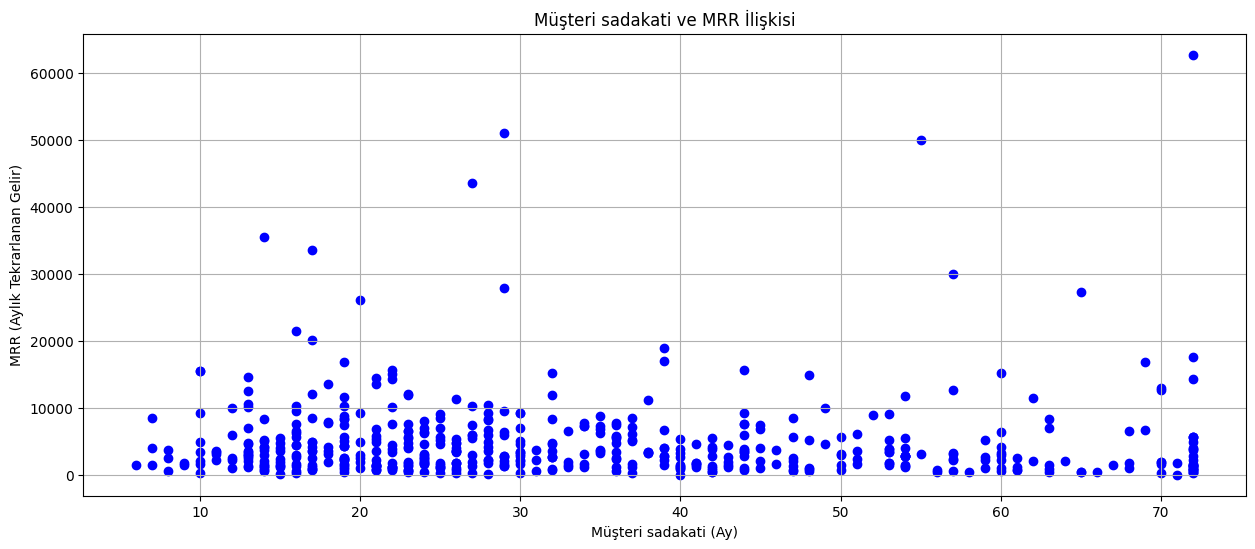

In [76]:
# Müşteri sadakati ve MRR arasındaki ilişki
plt.figure(figsize=(15, 6))
plt.scatter(rev_nps_mrr_age_df['Customer Age (Months)'], rev_nps_mrr_age_df['MRR'], color='blue')
plt.title('Müşteri sadakati ve MRR İlişkisi')
plt.xlabel('Müşteri sadakati (Ay)')
plt.ylabel('MRR (Aylık Tekrarlanan Gelir)')
plt.grid(True)
plt.show()

*Kullanım süreleri arasında homojen bir dağılım görünüyor.*

*Kullanım süresine baktığımızda müşteri yoğunluğunun 10 - 30 ay aralığında olduğunu görüyoruz ve aynı şekilde diğer sürelere oranla bu kısımda genel gelir daha fazla.*
     
*Bu çıkarımla müşteri tutma odaklı bir politika yerine yeni müşteri kazanma odaklı bir politika şirketin geliri için daha yararlı olacaktır.*


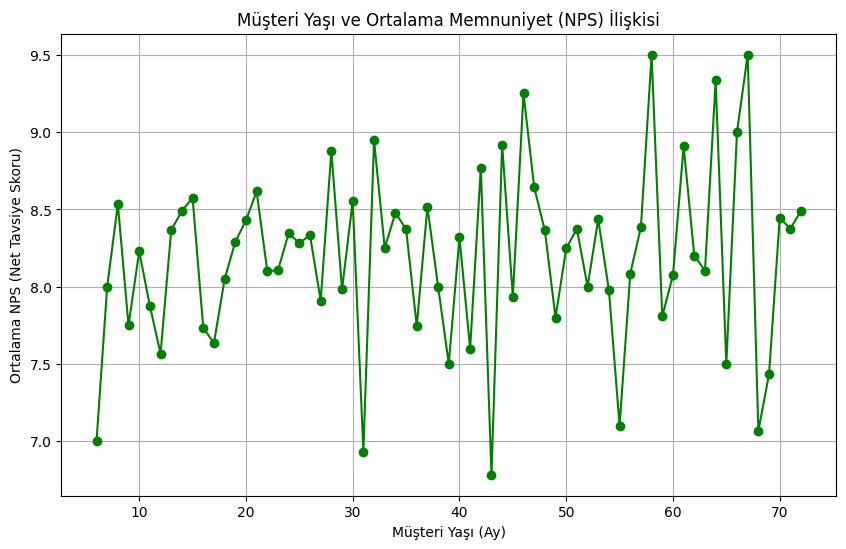

In [77]:
# Çizgi Grafiği: Müşteri sadakati ve ortalama memnuniyet (NPS) arasındaki ilişki
grouped_df = rev_nps_mrr_age_df.groupby('Customer Age (Months)')['NPS'].mean()

plt.figure(figsize=(10, 6))
plt.plot(grouped_df.index, grouped_df.values, marker='o', linestyle='-', color='green')
plt.title('Müşteri Yaşı ve Ortalama Memnuniyet (NPS) İlişkisi')
plt.xlabel('Müşteri Yaşı (Ay)')
plt.ylabel('Ortalama NPS (Net Tavsiye Skoru)')
plt.grid(True)
plt.show()

**Grafiği incelediğmizde daimi müşterilerde daha yüksek oran memnuniyet gözlemleniyor.**

**5-10 ay arasındaki kullanım sürelerinde gözle görülür bir artış var.**

**30-40 ay arasındaki kullanım sürelerinde anlık düşüşer yaşanıyor.**

**Genel olarak yorumladığımızda ortalama memnuniyet seviyesi kullanım süresine göre aynı oranda çıkıyor bu da platformun her yaş için uygun olduğunu gösteriyor.**

# 2. Memnuniyet ile Gelir Seviyesi 

**Amaç: Müşterinin gelir seviyesi memnuniyetini nasıl etkiliyor.**

**Veriler:**

* *Total Revenue (Toplam Gelir)*

* *How likely are you to recommend insider to a friend or colleague (NPS)*

In [78]:
# age_df
# mrr_df
# revenue_df

revenue_nps_df = rev_nps_mrr_age_df.loc[:, ['Customer ID', 'Total Revenue', 'NPS']]
revenue_nps_df = revenue_nps_df[revenue_nps_df['Total Revenue'] != 0].reset_index(drop=True)
revenue_nps_df

,Customer ID,Total Revenue,NPS
0,CRM-1470950,732199.0,7.333333
1,CRM-1506400,375135.0,9.500000
2,CRM-1485600,116732.0,8.500000
3,CRM-154400,27649.0,7.750000
4,CRM-1490400,52666.0,7.500000
...,...,...,...
434,CRM-1490750,91559.0,8.666667
435,CRM-833950,609401.0,8.000000
436,CRM-783450,16527.0,7.666667
437,CRM-155450,567026.0,6.666667


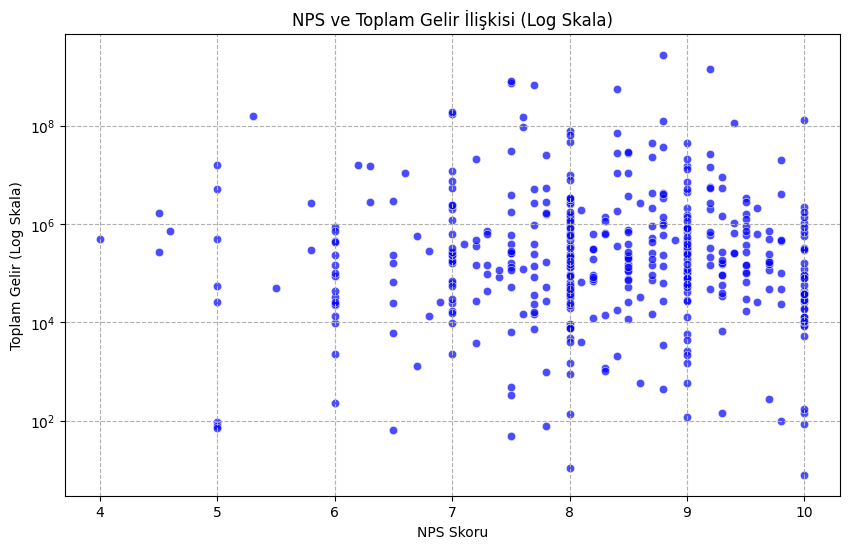

In [79]:
revenue_nps_df['NPS'] = revenue_nps_df['NPS'].round(1)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=revenue_nps_df, x='NPS', y='Total Revenue', alpha=0.7, color='b')

plt.yscale('log')  

plt.title('NPS ve Toplam Gelir İlişkisi (Log Skala)')
plt.xlabel('NPS Skoru')
plt.ylabel('Toplam Gelir (Log Skala)')
plt.grid(True, which="both", linestyle="--")
plt.show()



# 3. Müşteri Türüne Göre Tutulan, Kaybedilen ve Yeni Başlayan Müşteriler

In [84]:
import pandas as pd  # Veri işleme için pandas kütüphanesini içe aktarıyoruz.

# CSV dosyalarını pandas ile okuyoruz.
# - df_region: Bölge (Region) ve sektör (Vertical) bilgilerini içerir.
# - df_status: Müşteri durumları (Churn, Onboarding, Retained) ve seviyeleri içerir.
# - df_mrr: Müşterilerin aylık tekrar eden gelir (MRR) verilerini içerir.
df_region = pd.read_csv("/kaggle/input/datas/RegionAndVertical_Data.csv")
df_status = pd.read_csv('/kaggle/input/datas/StatusAndLevel_Data.csv')
df_mrr = pd.read_csv("/kaggle/input/datas/Customer_MRR_Data.csv")

# Müşteri durumlarını filtreleyerek farklı DataFrame'ler oluşturuyoruz.
# - Churn: Hizmeti bırakmış müşteriler.
# - Onboarding: Yeni kayıt olup sisteme giriş sürecinde olan müşteriler.
# - Retained: Hizmeti kullanmaya devam eden mevcut müşteriler.

df_status_churn = df_status[df_status['Status'] == 'Churn']  # Churn olan müşteriler
df_status_onboarding = df_status[df_status['Status'] == 'Onboarding']  # Onboarding sürecindeki müşteriler
df_status_retained = df_status[df_status['Status'] == 'Retained']  # Mevcut müşteriler (Retained)


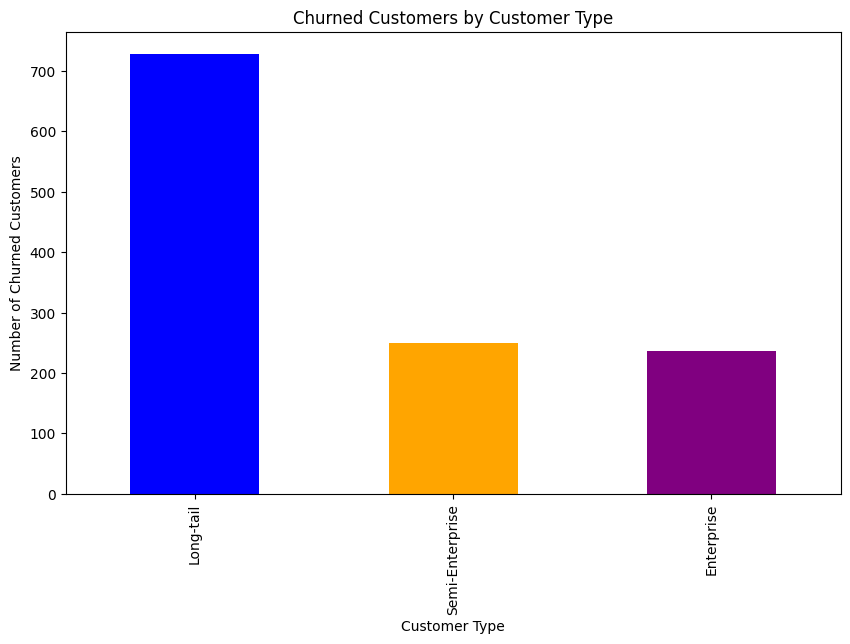

In [85]:
# Churn (hizmeti bırakmış) müşterilerin müşteri seviyelerine göre dağılımını hesaplıyoruz.
# - 'Customer Level' sütunundaki farklı müşteri seviyelerinin sayısını alıyoruz.
churn_counts = df_status_churn['Customer Level'].value_counts()


plt.figure(figsize=(10, 6))
churn_counts.plot(kind='bar', color=['blue', 'orange', 'purple'])
plt.xlabel('Customer Type')
plt.ylabel('Number of Churned Customers')
plt.title('Churned Customers by Customer Type')
plt.show()


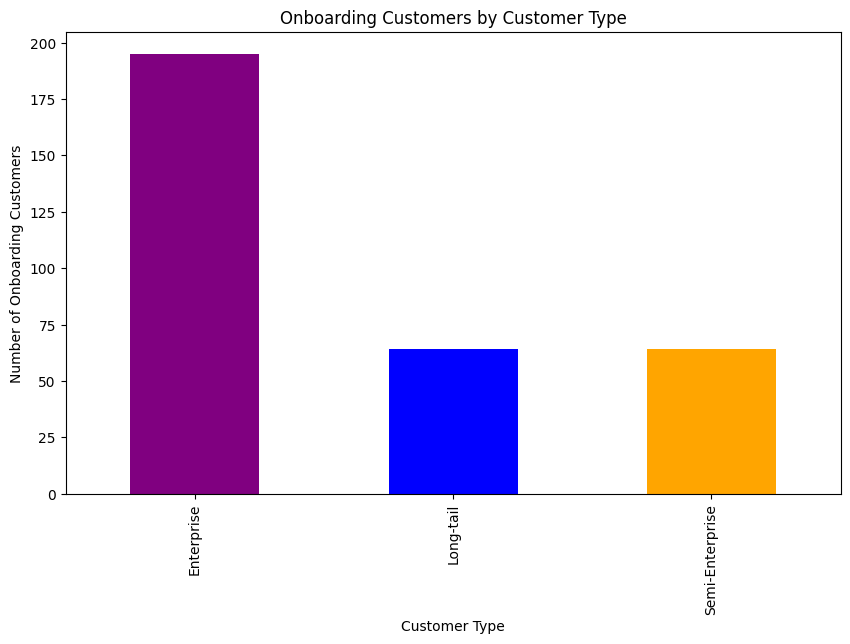

In [87]:
# Onboarding (sisteme yeni kayıt olan) müşterilerin müşteri seviyelerine göre dağılımını hesaplıyoruz.
# - 'Customer Level' sütunundaki farklı müşteri seviyelerinin sayısını alıyoruz.
onboarding_counts = df_status_onboarding['Customer Level'].value_counts()


plt.figure(figsize=(10, 6))
onboarding_counts.plot(kind='bar', color=['purple', 'blue', 'orange'])
plt.xlabel('Customer Type')
plt.ylabel('Number of Onboarding Customers')
plt.title('Onboarding Customers by Customer Type')

plt.show()


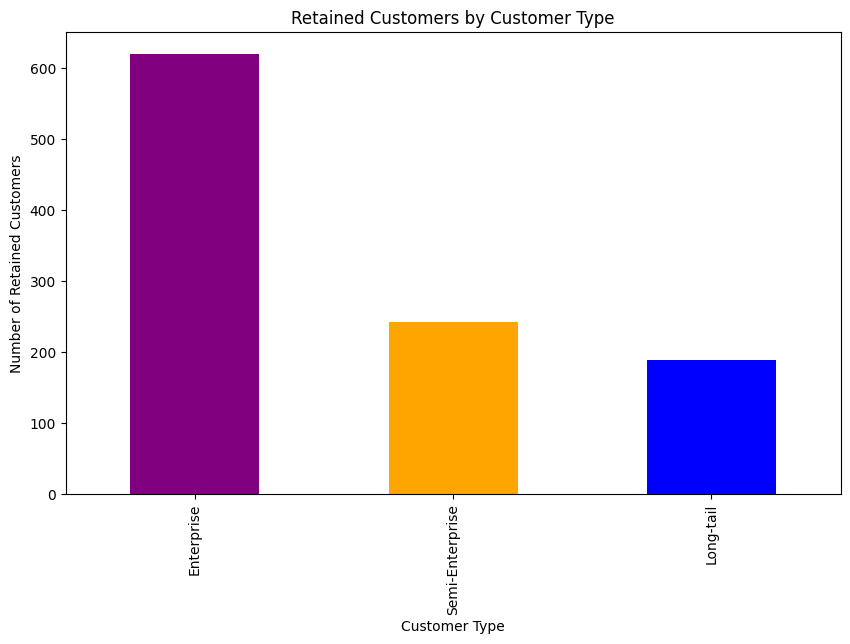

In [103]:
# 'Retained' müşterileri filtreleyerek ayrı bir DataFrame oluşturuyoruz.
# - Retained: Hizmeti kullanmaya devam eden mevcut müşteriler.
df_status_retained = df_status[df_status['Status'] == 'Retained']

# Mevcut müşterilerin müşteri seviyelerine göre dağılımını hesaplıyoruz.
# - 'Customer Level' sütunundaki farklı müşteri seviyelerinin sayısını alıyoruz.
retained_counts = df_status_retained['Customer Level'].value_counts()


plt.figure(figsize=(10, 6))
retained_counts.plot(kind='bar', color=['purple', 'orange', 'blue'])
plt.xlabel('Customer Type')
plt.ylabel('Number of Retained Customers')
plt.title('Retained Customers by Customer Type')

plt.show()


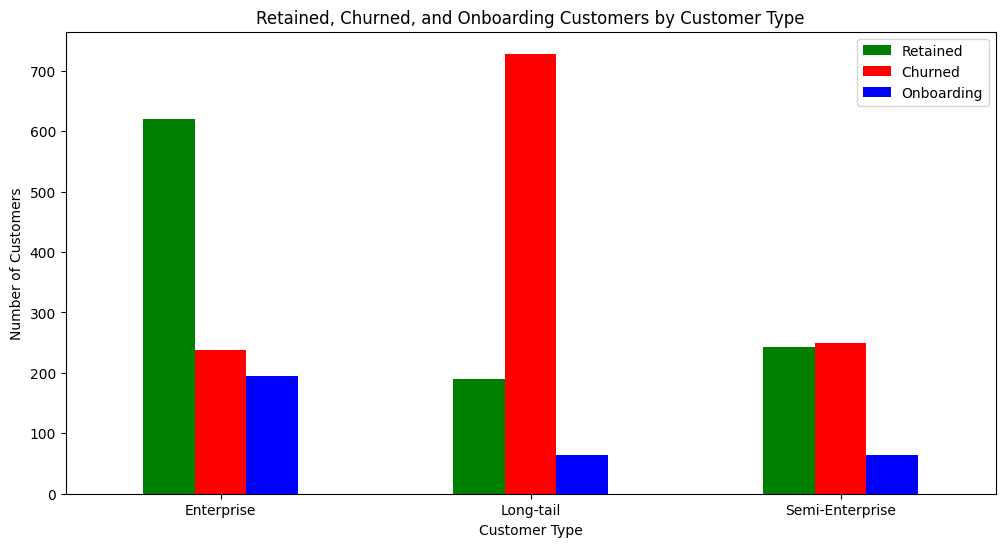

In [90]:
# Müşteri durumlarına göre müşteri seviyelerinin sayısını hesaplıyoruz.
# - Retained: Hizmeti kullanmaya devam eden müşteriler.
# - Churned: Hizmeti bırakan müşteriler.
# - Onboarding: Sisteme yeni kayıt olan müşteriler.
retained_counts = df_status_retained['Customer Level'].value_counts()
churn_counts = df_status_churn['Customer Level'].value_counts()
onboarding_counts = df_status_onboarding['Customer Level'].value_counts()

# Tüm müşteri seviyelerini içeren bir DataFrame oluşturuyoruz.
# - Her müşteri seviyesinin 'Retained', 'Churned' ve 'Onboarding' durumlarını içermesini sağlıyoruz.
# - .fillna(0) kullanarak eksik değerleri 0 ile dolduruyoruz (örneğin, bir kategori belirli bir grupta yoksa 0 olacak).
combined_counts = pd.DataFrame({
    'Retained': retained_counts,
    'Churned': churn_counts,
    'Onboarding': onboarding_counts
}).fillna(0)


combined_counts.plot(kind='bar', figsize=(12, 6), color=['green', 'red', 'blue'])
plt.xlabel('Customer Type')
plt.ylabel('Number of Customers')
plt.title('Retained, Churned, and Onboarding Customers by Customer Type')
plt.xticks(rotation=0)
plt.show()


**Ayrılan Müşterilere bakılınca müşterilerin çoğunun Long-tail müşterisi olduğunu görüyoruz. Long-tail ciddi bir müşteri kaybı problemi olduğunu ve bu da müşteri sadakatinin düşük olduğunu gösterir. Long-tail satış modeli hakkında ciddi bir soruşturma yapılması gerekiyor. Bunun için ürünler ve hizmet hakkında şu sorular sorulabilir:**

**1. Fiyatlandırma mı yüksek?**
**2. Ürün müşterilerin beklentilerini mi karşılamıyor?**
**3. Hedef müşteri kitlesi tam olarak kim ve nasıl ulaşabiliriz?**


***Long-tail modeli*, az talep gören ama geniş bir yelpazeye yayılan ürünlerin satışına odaklanır. Her ürünün satış miktarı düşük olsa da, toplamda büyük bir gelir elde edilebilir.**
**Şirket özelleştirilmiş ürünler yerine daha basit ve daha çok talep edilen ürünlerin üretimine ve satışına yönelirse satışlarda ve gelirde gözle görülebilir bir artış görülecektir.**

**En çok yeni müşteri çeken Customer Levelin *Enterprise* olduğunu görebiliyoruz. Bundan başka olarak en çok kalan müşteri miktarı da Enterprisedadır. Bu bize Enterprise modelinin müşteriler tarafından daha çok beğenildiğini gösterir. Onboarding sayısının diğerlerinden fazla olması da Enterprise'ın büyümeye devam ettiğini gösteriyor. Bu model gelecek vaat ettiği için daha çok büyümeye ve büyümeyi devam ettirmeye yönelik stratejiler kullanmılıdır.**

**Semi Enterprise alanında kalan müşteri sayısına yakın bir miktarda müşteri de ayrılmıştır. Bu model diğerlerine kıyasla daha stabildir. Belli bir stratejik değişimin tartışılmasına gerek yoktur.**

# 4. Bölgesel Dağılımlar Üzerinden Çıkarımlar

In [107]:
#  df_region ve df_status veri kümelerini Customer ID sütunu üzerinden birleştiriyoruz.
df_merged = pd.merge(df_region, df_status, on='Customer ID', how='inner')

df_merged_without_mrr = df_merged

# 'Status' değeri 'Churn' olan müşterileri filtreleyerek, MRR olmadan churn müşterileri içeren bir DataFrame oluşturuyoruz.
df_churn_without_mrr = df_merged[df_merged['Status'] == 'Churn']

# Müşteri verilerine df_mrr (MRR verisi) veri setini ekliyoruz.
# -Customer ID sütunu üzerinden eşleşen verileri getiriyoruz.
df_merged = pd.merge(df_merged, df_mrr, on='Customer ID', how='inner')

# MRR ile güncellenmiş birleşik veri kümesini kaydediyoruz.
df_merged_with_mrr = df_merged

# MRR ile birlikte, Status değeri Churn olan müşterileri filtreleyerek yeni bir DataFrame oluşturuyoruz.
df_churn_with_mrr = df_merged[df_merged['Status'] == 'Churn']


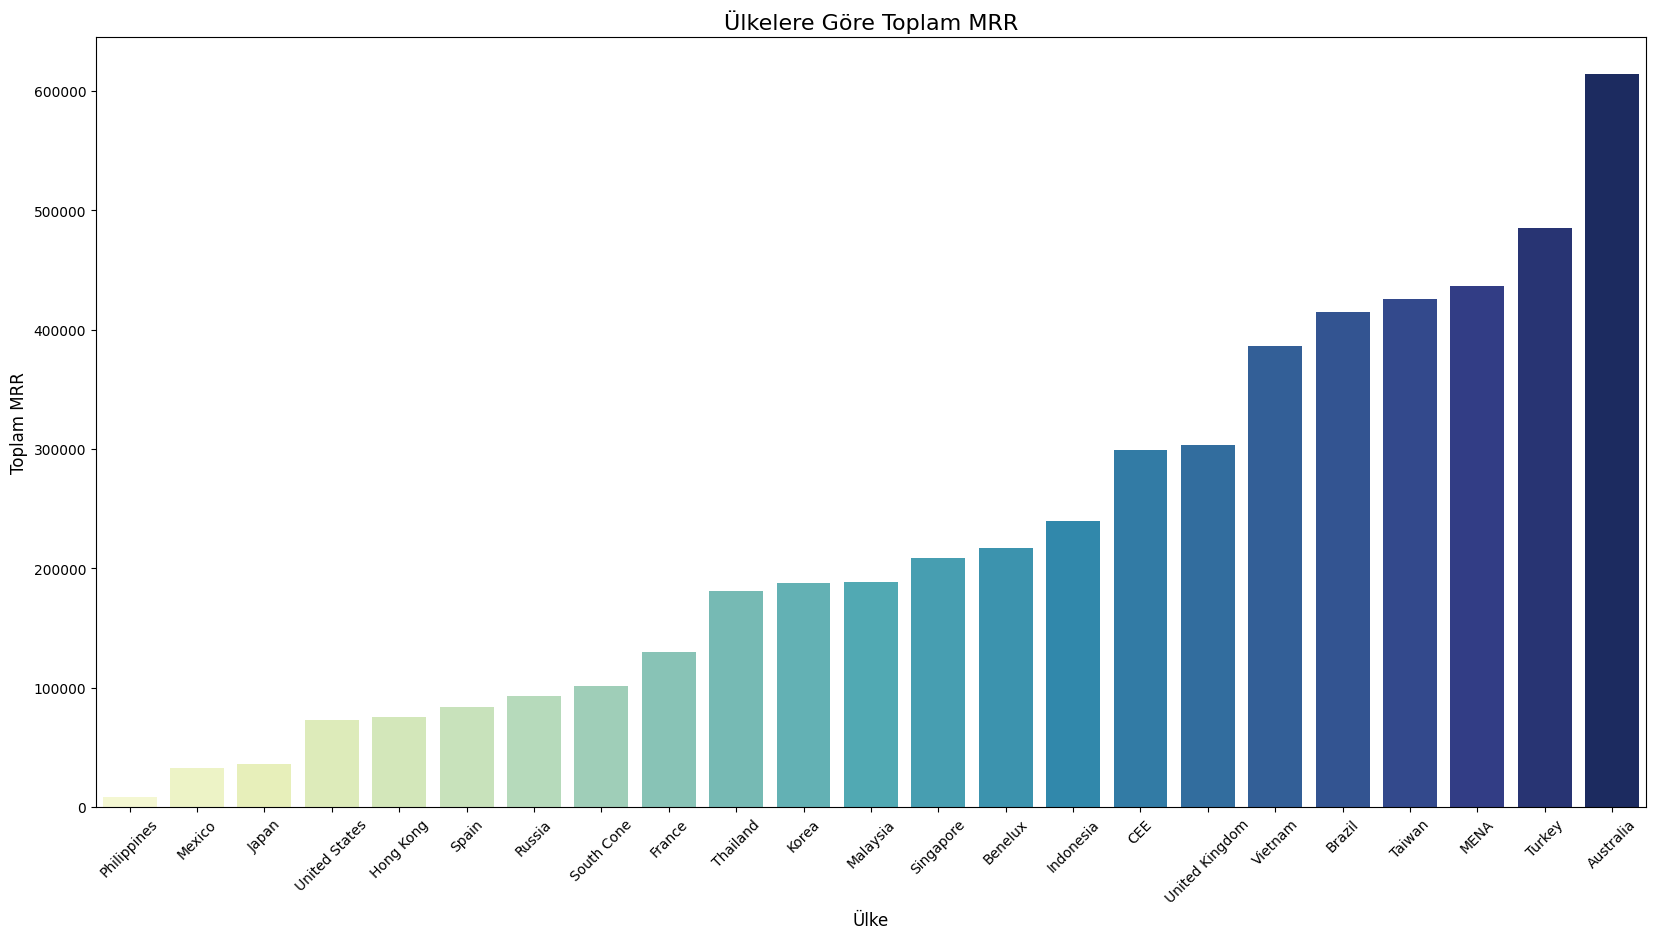

In [108]:
#  $ , gibi sayıya çevrilmesini engelleyen karakterleri kaldırıyoruz.
df_merged['MRR'] = df_merged['MRR'].astype(str).str.replace(r'[^\d.]', '', regex=True)

# Temizlenen MRR verisini sayısal (float) formata çeviriyoruz.
df_merged['MRR'] = pd.to_numeric(df_merged['MRR'], errors='coerce')

# Region (Bölge) bazında gruplayarak her bölgedeki toplam MRR değerini hesaplıyoruz.
region_mrr = df_merged.groupby('Region')['MRR'].sum().reset_index()

# MRR değerlerine göre sıralama yapıyoruz (artan sırada).
region_mrr = region_mrr.sort_values(by='MRR', ascending=True)


plt.figure(figsize=(20, 10))
sns.barplot(data=region_mrr, x='Region', y='MRR', palette='YlGnBu')
plt.title('Ülkelere Göre Toplam MRR', fontsize=16)  
plt.xlabel('Ülke', fontsize=12) 
plt.ylabel('Toplam MRR', fontsize=12)  


plt.xticks(rotation=45)

plt.show()


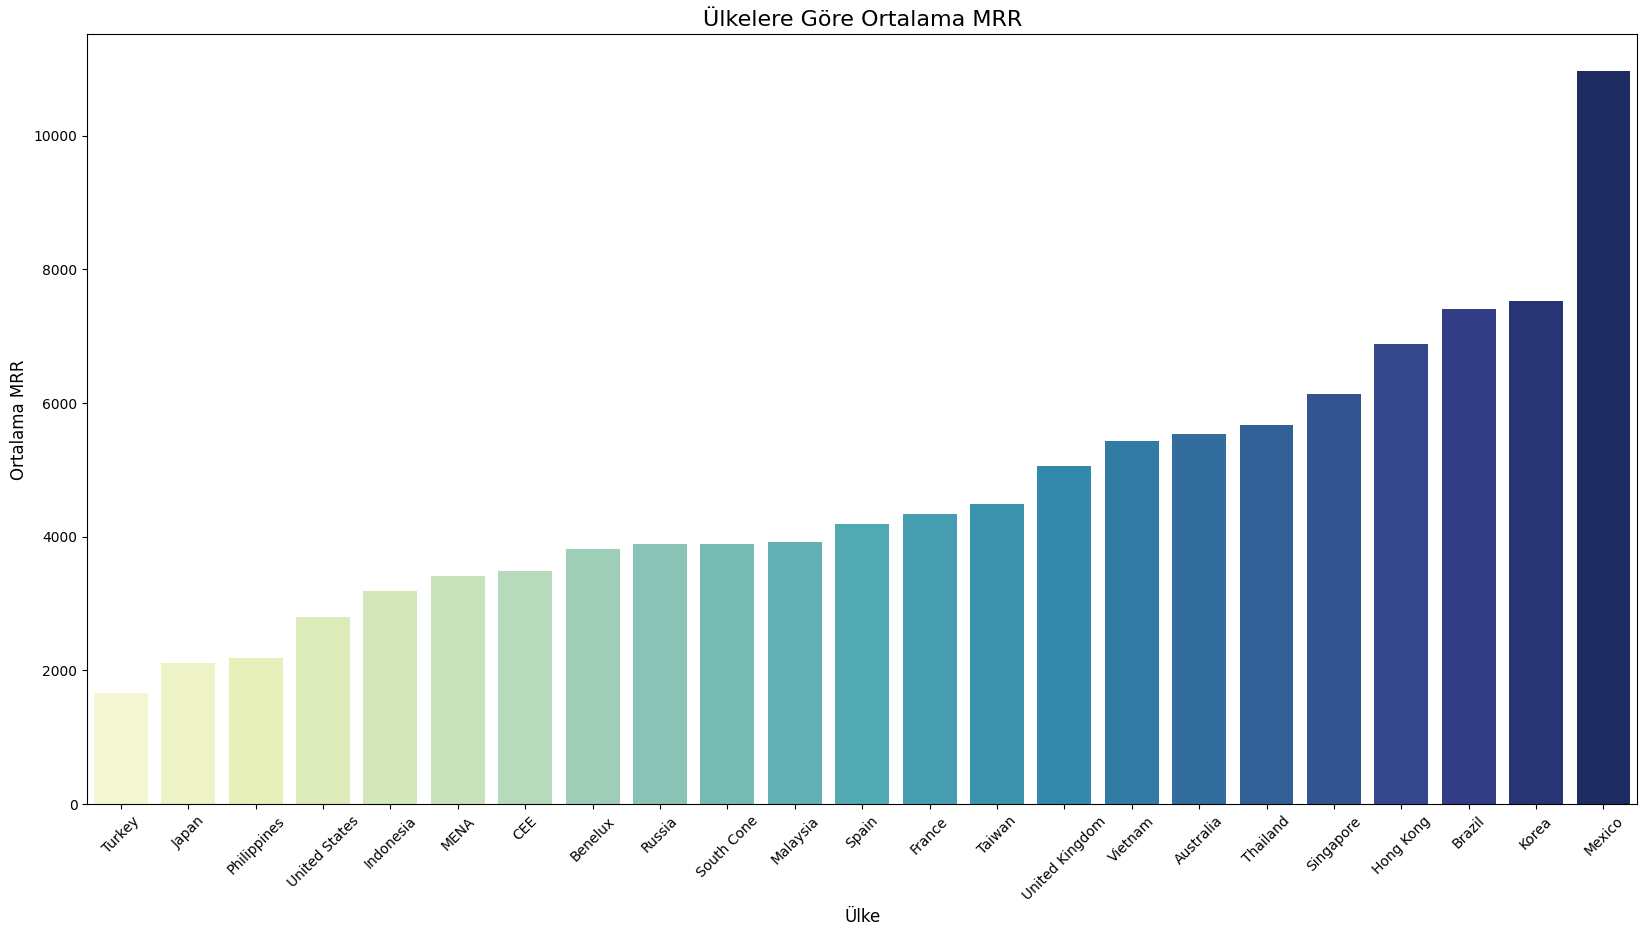

In [109]:
# Region (Bölge) bazında gruplayarak her bölgedeki ortalama MRR değerini hesaplıyoruz.
region_mrr = df_merged.groupby('Region')['MRR'].mean().reset_index()

# Ortalama MRR değerlerine göre sıralama yapıyoruz (artan sırada).
region_mrr = region_mrr.sort_values(by='MRR', ascending=True)

plt.figure(figsize=(20, 10))
sns.barplot(data=region_mrr, x='Region', y='MRR', palette='YlGnBu')
plt.title('Ülkelere Göre Ortalama MRR', fontsize=16)  
plt.xlabel('Ülke', fontsize=12) 
plt.ylabel('Ortalama MRR', fontsize=12)  
plt.xticks(rotation=45)


plt.show()

**Meksikanın toplam MRR grafiğinde sondan ikinci ama ortalama MRR grafiğinde birinci olması bize meksikadaki iş bölümünün az insandan oluştuğunu ama kişi başı kullanıcının kazandırdığı ortalama MRR ın çok yüksek olduğunu gösterir. Bu bize meksikadaki kullanıcılıların şirket geliri için daha değerli olduğunu göstermektedir.**

**Türkiye ortalama MRR dan sonuncu iken toplam MRR'da baştan ikinci olması Türkiye'de fazla insan gücü olduğunu ama kişi başı sağlanan gelirin çok düşük olduğunu gösterir.**

**Meksikada yapılan çalışmalar verimlilik açısından çok yüksek bir seviyededir. Meksikada yapılan çalışmaların teknikleri ve kullanıcıların önerileri ön plana çıkarılarak diğer Ülkelerdeki verimlilik arttırılabilir böylece genel MRR'ın yükselme eğilimine geçmesi sağlanabilir.**

**Grafikler karşılaştırıldığınd Filipinlerin iki grafikte de düşük sırada olduğu görülmektedir. Bu hem iş gücünün hem de kişi başı MRR'ın düşük olduğunu gösterir. Filipinler gibi ülkeler göz önünde bulundurularak verimlilik arttırma çalışmaları yapıldığında iş gücü az olsa bile Toplam MRR da bir artış olacaktır.**

**Meksika ,Türkiye  ve Filipinler sadece verdiğmiz üç örnektir. Ülkelerin MRR a göre ortalama ve toplam grafiğinde bakarak hangi ülkelerin verimlilik açısından gelişime ihtiyaç duyulduğu tespit edilebilir ve yeni çalışmalar öne sunulabilir.**

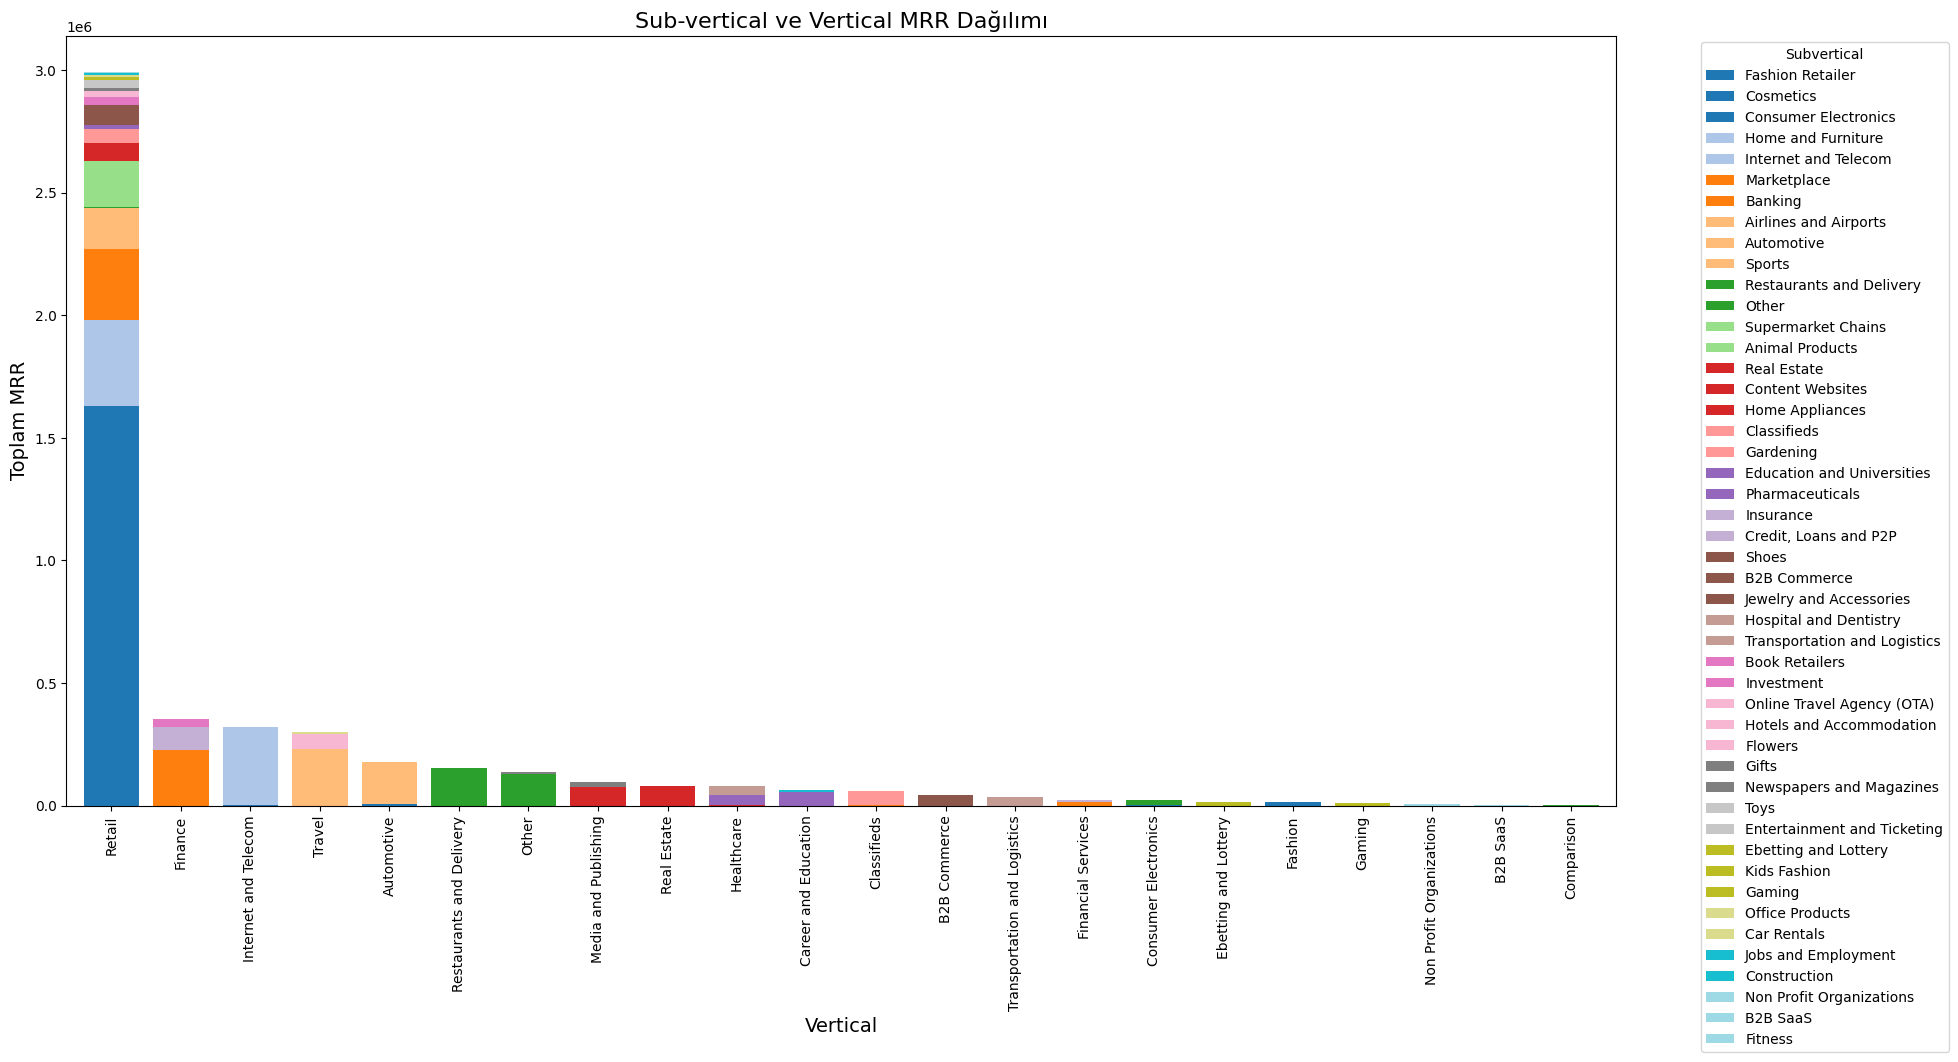

In [110]:
# MRR sütununu sayısal formata çeviriyoruz.
df_merged_with_mrr["MRR"] = pd.to_numeric(df_merged_with_mrr["MRR"], errors="coerce")

df_merged_with_mrr.dropna(subset=["MRR"], inplace=True)

# MRR değeri negatif olan satırları veri setinden çıkarıyoruz.
df_merged_with_mrr = df_merged_with_mrr[df_merged_with_mrr["MRR"] >= 0]

# Vertical  ve Subvertical  kategorilerine göre MRR değerlerini toplayarak bir pivot tablo oluşturuyoruz.
mrr_pivot = df_merged_with_mrr.pivot_table(index="Vertical", columns="Subvertical", values="MRR", aggfunc="sum")

mrr_pivot.fillna(0, inplace=True)

# Pivot tablosunun her sütununun toplamını alıp, toplam MRR değerine göre sütunları azalan sırayla sıralıyoruz.
mrr_pivot = mrr_pivot[mrr_pivot.sum(axis=0).sort_values(ascending=False).index]

# Pivot tablosunun her satırının toplamını alıp, toplam MRR değerine göre satırları azalan sırayla sıralıyoruz.
mrr_pivot = mrr_pivot.loc[mrr_pivot.sum(axis=1).sort_values(ascending=False).index]


mrr_pivot.plot(kind="bar", stacked=True, figsize=(20, 10), colormap="tab20", width=0.8)
plt.xlabel("Vertical", fontsize=14)  
plt.ylabel("Toplam MRR", fontsize=14) 
plt.title("Sub-vertical ve Vertical MRR Dağılımı", fontsize=16) 
plt.legend(title="Subvertical", bbox_to_anchor=(1.05, 1), loc="upper left")


plt.show()


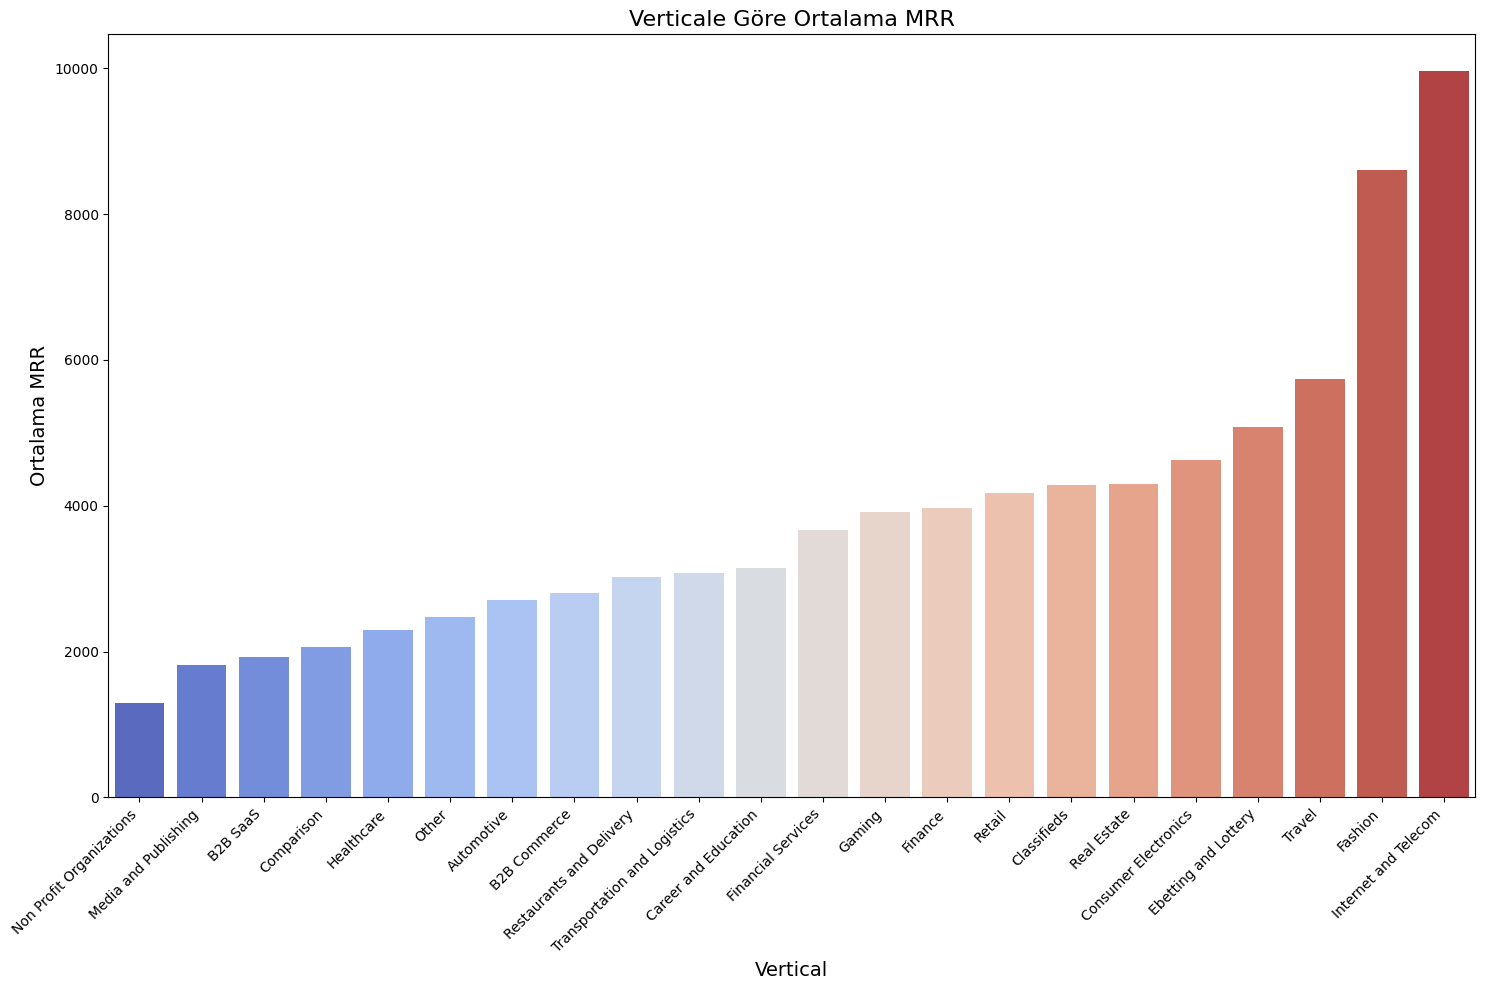

In [111]:
# Vertical kategorilerine göre MRR ortalamalarını hesaplıyoruz.
mrr_by_vertical = df_merged_with_mrr.groupby("Vertical")["MRR"].mean().reset_index()

mrr_by_vertical = mrr_by_vertical.sort_values(by="MRR", ascending=True)

plt.figure(figsize=(15, 10))
sns.barplot(data=mrr_by_vertical, x="Vertical", y="MRR", palette="coolwarm")

plt.xlabel("Vertical", fontsize=14)
plt.ylabel("Ortalama MRR", fontsize=14)
plt.title("Verticale Göre Ortalama MRR", fontsize=16)
plt.xticks(rotation=45, ha='right')


plt.tight_layout()
plt.show()

**Hacim olarak en çok MRR değerine sahip Vertical, Retail'dir. Retail Verticala MRR anlamında en çok katkı sağlayan sub-vertical *Fashion Retaildır*. Fashion Retail Şirkete para kazandıran en büyük kısım. Bu trendi kaybebetmemek için Fashion Retail kısmında büyümeye geçilebilir.**

**Fashion Ve Internet and Telecom alanları Retail kadar hacime sahip olmasa da Ortalama MRR grafiğine baktığımızda ilk ikide durmaktadır. Bu az miktarda pazar hareketi olmasına rağmen diğerlerinden daha fazla gelir getirdiklerini gösterir. Internet and Telecom ve Fashion bölümlerinde büyümeye geçmek mantıklı olacaktır. Internet and Telecom ve Fashion alanlarında pazar hacmi arttırma ve yeni müşterleri çekme yönünde çalışmalar yapılırsa Toplam MRR grafiğinde önemli bir miktarda artış görüleceği söylenebilir.**

# Ticket MRR Çözülme Saati

In [115]:
df_ticket = pd.read_csv("/kaggle/input/datas/Help_Ticket_Data.csv")

df_mrr_copy = df_mrr.copy()

df_mrr_copy['MRR'] = df_mrr_copy['MRR'].astype(str).str.replace(r'[^\d.]', '', regex=True)

df_mrr_copy['MRR'] = pd.to_numeric(df_mrr_copy['MRR'], errors='coerce')

df_mrr_ticket = pd.merge(df_mrr_copy, df_ticket, on='Customer ID', how='inner')

df_mrr_ticket['Hour to ticket Ratio'] =  df_mrr_ticket['Help Ticket Lead Time (hours)'] / df_mrr_ticket['Help Ticket Count']

df_mrr_ticket.head(10)

,Customer ID,MRR,Help Ticket Count,Help Ticket Lead Time (hours),Hour to ticket Ratio
0,CRM-673950,4950,32,1307,40.843750
1,CRM-683100,600,4,1475,368.750000
2,CRM-150500,17650,443,844,1.905192
3,CRM-701050,1350,5,1403,280.600000
4,CRM-730800,2125,9,740,82.222222
5,CRM-902900,5590,31,670,21.612903
6,CRM-229950,700,4,389,97.250000
7,CRM-950450,2664,17,744,43.764706
8,CRM-1025800,2300,9,965,107.222222
9,CRM-1100500,3299,21,1355,64.523810


In [116]:
correlation_hours = df_mrr_ticket['MRR'].corr(df_mrr_ticket['Help Ticket Lead Time (hours)'])

correlation_tickets = df_mrr_ticket['MRR'].corr(df_mrr_ticket['Help Ticket Count'])

ticket_to_hours = df_mrr_ticket['MRR'].corr(df_mrr_ticket['Hour to ticket Ratio'])

print(f"MRR ve Yardım Talebi Bekleme Süresi (saat) arasındaki korelasyon: {correlation_hours}")
print(f"MRR ve Help Ticket Sayısı arasındaki korelasyon: {correlation_tickets}")
print(f"MRR'ın Ticketların çözülme saatlerine oranına oranı: {ticket_to_hours}")

MRR ve Yardım Talebi Bekleme Süresi (saat) arasındaki korelasyon: -0.04152015973631763
MRR ve Help Ticket Sayısı arasındaki korelasyon: 0.35529056279704296
MRR'ın Ticketların çözülme saatlerine oranına oranı: -0.12411830882067368


<ipython-input-118-5953ce10f41d>:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  category_mrr = df_mrr_ticket.groupby('Lead Time Category')['MRR'].mean().reset_index()
/usr/local/lib/python3.10/dist-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


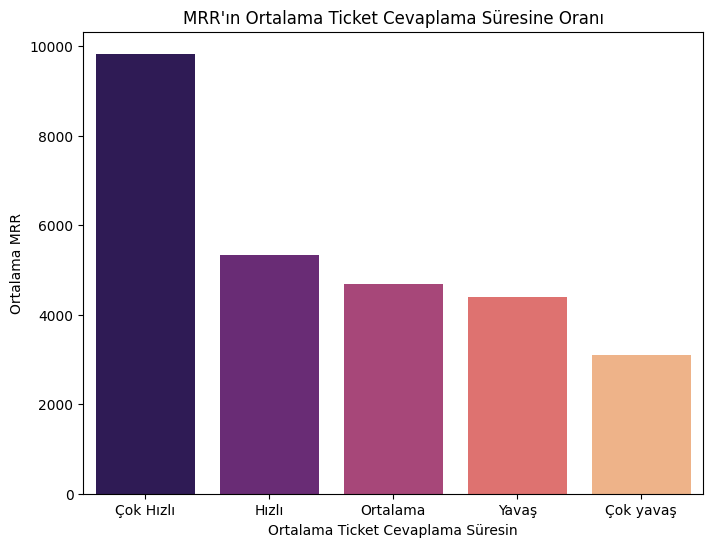

In [118]:
bins = [0, 10, 20, 30, 50, float('inf')]  # Define bin edges
labels = ['Çok Hızlı', 'Hızlı', 'Ortalama', 'Yavaş', 'Çok yavaş']  # Define labels

df_mrr_ticket['Lead Time Category'] = pd.cut(df_mrr_ticket['Hour to ticket Ratio'], bins=bins, labels=labels, right=False)

#Aggregate total MRR for each category
category_mrr = df_mrr_ticket.groupby('Lead Time Category')['MRR'].mean().reset_index()

#Plot the results
plt.figure(figsize=(8, 6))
sns.barplot(x='Lead Time Category', y='MRR', data=category_mrr, palette='magma')

plt.xlabel('Ortalama Ticket Cevaplama Süresin')
plt.ylabel('Ortalama MRR')
plt.title("MRR'ın Ortalama Ticket Cevaplama Süresine Oranı")

plt.show()

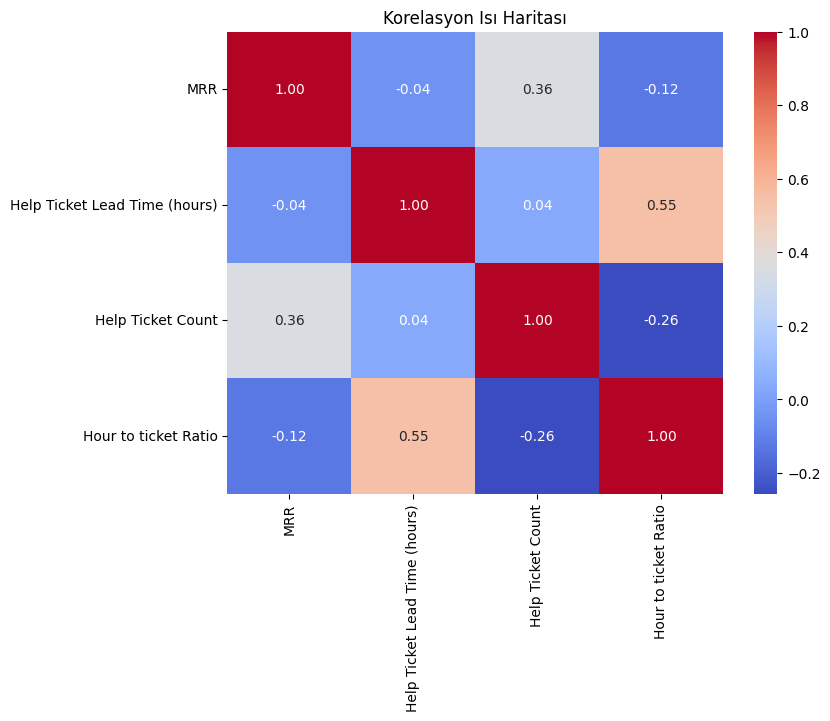

In [119]:
corr_matrix = df_mrr_ticket[['MRR', 'Help Ticket Lead Time (hours)', 'Help Ticket Count', 'Hour to ticket Ratio']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', cbar=True)

plt.title('Korelasyon Isı Haritası')
plt.show()

**Burada aralarındaki bağlantıyı bulmak için Pearson Correlation tekniğini kullandık. Sonucun eksi olması inverse bir ilerleme gösterir. Yani 
birisi yükseldikçe diğerinin düştüğünü söyler.**

**MRR ile Help Ticket Lead Time arasındaki korelasyon eksiyi gösteriyor. Bu bize bir ticketin çözülme süresinin arttığında müşterinin aylık 
kazancının düştüğünü gösterir.**

**MRR ile Help Ticket Count arasındaki korelasyon artıyı gösteriyor. Bu bize müşterinin aylık kazancı ile ticket verme arasında pozitif bir gelişim
olduğunu gösterir. Help Ticket Lead Time eksi etki gösterirken bile ticket sayısı ile MRR arasında bir artı etkileşim olması bize daha çok 
ticket veren müşterinin MRR da büyük bir artış yaşadığını gösterir. Yani ticket verilmesi müşteri kazancı için pozitif bir eylem olarak bakılabilir.**

**Ticket vermenin direkt kazanç olarak bakmak yanlış bir yorum olduğu söylenebilirdi ama üçüncü korelasyon bu görüşü devre dışı bırakıyor. 
MRR ile her bir ticketın ne kadar sürede çözüldüğünün ortalaması karşılaştırıldığında eksi bir etki görüyoruz. Burada ortalama bir ticketın 
ne kadar uzun sürede çözüme kavuşursa MRR'ın o kadar azaldığını anlıyoruz. Yani bir ticket ne kadar hızlı çözülürse MRR da o orantıyla
artıyor. Bu da bize ticketların çözülme hızının MRR ile önemli bir bağlantısı olduğunu öne sürer.**

**Bu veriler de genelleme olarak doğru gözükse de tabii ki de istisnalar olacaktır bunları göz ardı ettik**

**Help Ticket Lead Time ın bu kadar yüksek olması IT ve HR teaminin azlığından ya da performans eksiliğinden kaynaklanabilir. Bu takımlara yapılacak gelişmeler MRR'ı ve böylelikle şirketi iyi 
anlamda etkileyecektir. IT teame yeni recruitler ,çalışanların genel performansları hakkında bir değerlendirme ve ticketları verenlerle 
çözümleyenler arasında daha iyi bir ilişki kurma çabalarını içeren yeni etkinlikler şirketi iyi yönde etkileyecektir**

## ***GENEL YORUM***

In [164]:
df_survey = pd.read_csv("/kaggle/input/datas/CSAT_Survey_Data.csv")
df_users = pd.read_csv("/kaggle/input/my-data/output_file.csv")

In [165]:
merged_df = df_survey.merge(df_users)

merged_df["MRR"] = merged_df["MRR"].replace(r'[\$,]', '', regex=True).astype(float)
merged_df["Total Revenue"] = merged_df["Total Revenue"].replace(r'[\$,]', '', regex=True).astype(float)

In [166]:
print(merged_df.dtypes)

Customer ID                                                                   object
Year                                                                           int64
Quarter                                                                        int64
Survey Date                                                                   object
Response Date                                                                 object
How likely are you to recommend insider to a friend or colleague               int64
How would you rate the value you gain from our company                         int64
How frequently are you using our platform                                     object
Please rate the overall quality of our products                                int64
Please rate the usability of the panel                                       float64
Please rate your understanding of our reporting capabilities in the panel     object
level_0                                                          

In [167]:
merged_df.drop(merged_df[merged_df["Total Revenue"] == 0].index, inplace=True)
merged_df = merged_df.dropna()
merged_df = merged_df.drop(['level_0', 'index', 'Year', 'Quarter'], axis=1).reset_index(drop=True)
merged_df.head(10)

,Customer ID,Survey Date,Response Date,How likely are you to recommend insider to a friend or colleague,How would you rate the value you gain from our company,How frequently are you using our platform,Please rate the overall quality of our products,Please rate the usability of the panel,Please rate your understanding of our reporting capabilities in the panel,Customer Age (Months),...,Total Revenue,Help Ticket Count,Help Ticket Lead Time (hours),Company Newsletter Interaction Count,Product Bug Task Count,Region,Vertical,Subvertical,Status,Customer Level
0,CRM-1470950,2022-01-01,2022-03-25,4,3,Once a Day,2,3.0,I need someone from Insider team to provide me...,22.0,...,732199.0,30.0,366.0,3.0,160.0,Thailand,Retail,Marketplace,Retained,Enterprise
1,CRM-1470950,2022-07-01,2022-09-30,6,3,Once a Week,4,4.0,I tried but could not find everything I need,22.0,...,732199.0,30.0,366.0,3.0,160.0,Thailand,Retail,Marketplace,Retained,Enterprise
2,CRM-1470950,2022-04-01,2022-06-23,10,5,Once a Day,4,3.0,I need someone from Insider team to provide me...,22.0,...,732199.0,30.0,366.0,3.0,160.0,Thailand,Retail,Marketplace,Retained,Enterprise
3,CRM-1470950,2022-01-01,2022-03-28,7,4,Once a Day,4,4.0,I need someone from Insider team to provide me...,22.0,...,732199.0,30.0,366.0,3.0,160.0,Thailand,Retail,Marketplace,Retained,Enterprise
4,CRM-1470950,2022-01-01,2022-03-28,9,5,Once a Week,5,5.0,I am able to report everything easily,22.0,...,732199.0,30.0,366.0,3.0,160.0,Thailand,Retail,Marketplace,Retained,Enterprise
5,CRM-1470950,2022-07-01,2022-08-05,8,4,Once a Week,4,4.0,I tried but could not find everything I need,22.0,...,732199.0,30.0,366.0,3.0,160.0,Thailand,Retail,Marketplace,Retained,Enterprise
6,CRM-355050,2022-04-01,2022-04-12,5,4,Once a Day,4,4.0,"I can pull all the numbers, but don't understa...",55.0,...,87728.0,13.0,981.0,5.0,80.0,Turkey,Retail,Fashion Retailer,Retained,Enterprise
7,CRM-355050,2022-07-01,2022-09-20,7,3,Once a Day,3,4.0,I tried but could not find everything I need,55.0,...,87728.0,13.0,981.0,5.0,80.0,Turkey,Retail,Fashion Retailer,Retained,Enterprise
8,CRM-165900,2022-01-01,2022-02-01,10,3,Once a Day,5,4.0,I need someone from Insider team to provide me...,72.0,...,92663.0,23.0,1393.0,4.0,150.0,Turkey,Retail,Fashion Retailer,Retained,Enterprise
9,CRM-165900,2022-01-01,2022-03-28,10,5,Once a Week,5,4.0,I need someone from Insider team to provide me...,72.0,...,92663.0,23.0,1393.0,4.0,150.0,Turkey,Retail,Fashion Retailer,Retained,Enterprise


In [168]:
# Sayısal sütunları seç
numeric_columns = merged_df.select_dtypes(include=['float64', 'int64'])

# Korelasyon matrisini oluştur
corr_matrix = numeric_columns.corr()

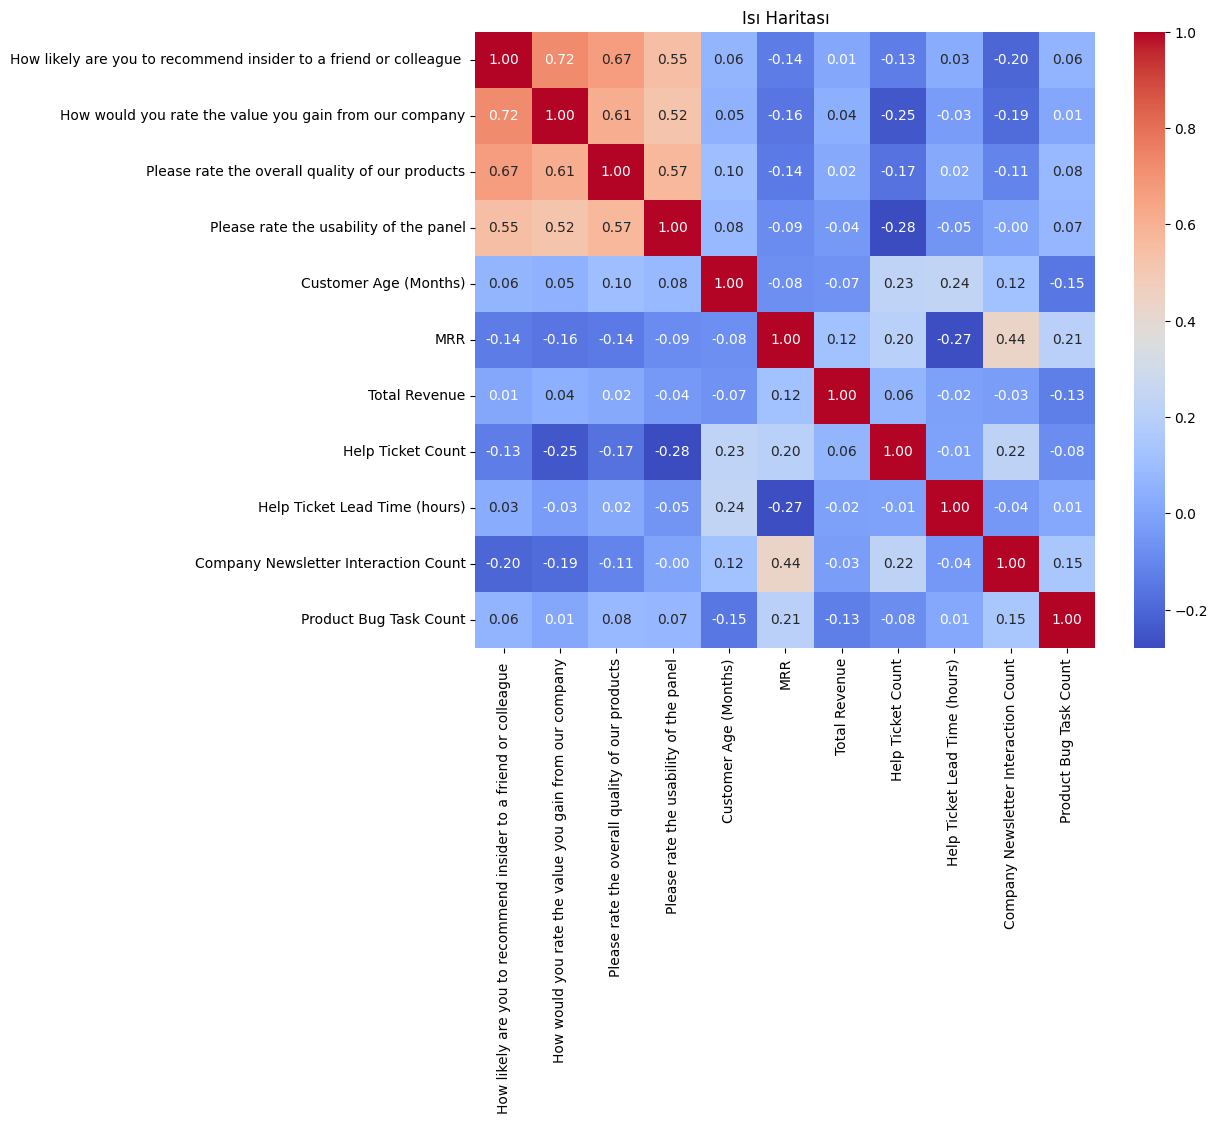

In [169]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Isı Haritası')
plt.show()

**Veri setleri temizlendikten ve düzenlendikten sonra genel oluşturulmuş ısı haritasının yorumu:**

**Bu ısı haritasının amacı bize genel olarak birbirini etkileyen farkedilmesi kolay olmayan maddeleri göstermektir. Isı haritasının en çok dikkat çeken yeri olan en üst soldaki kısıma baktığımızda "uygulamayı arkadaşlarınıza ne sıklıkla öneririrsiniz" "ürünün kalitesine ne puan verirsiniz" "Panelin kaliteisine ne paun verirsiniz" ve "şirketten kazandığınız paraya ne puan verirsiniz" kısımlarının daha kırmızı ve 1 e yakın korelasyon puanları aldığını görüyürouz bu birbirisi arasındaki ilişkinin daha yüksek olduğunu anlatıyor ve genel olarak ısı haritasının güvenirliğinin yüksek olduğunu belirtiyor. Ayrıca haritanın en güvenilir korelasyonu da burada yer alıyor "uygulamayı arkadaşlarınıza ne sıklıkla öneririrsiniz" ve "şirketten kazandığınız paraya ne puan verirsiniz" arasındaki korelasyon puanı 0.72. Bu oran 1 e çok yakın olması genel olarak kullanıcıların kazandığı paraların uygulamanın panelin vb diğer özelliklerinden çok daha önce çıktığı birisine önermeleri için en önemli unsurun kazandıkları parayı çok görmeleri olarak anlaşılabilir.**

**Burdan sonra genel ısı haritasının bize kazandırdığı bir diğer karşılaştırma seçeneği "şirketin bülteni ile etkileşim sayısı" ile "MRR" arasındaki ilişki. Bu korelasyon oranı 0.45 ve "MRR"ın edindiği en yüksek korelasyon oranı. Bu ilişki bültene tıklayan kişilerin daha çok para ödediğini gösteriyor. aynı zamanda MRR ın "bug sorunu sayısı" ile "yardım talep sayısı" de azımsanmayacak bir ilişki oranı var. Genel olarak bunların açıklaması şirketin ürünü paneli vb ile daha çok ilgilenen ve daha çok çabalayan kişilerin şirkete ödediği paraların da daha yüksek olduğunu gösteriyor.
"Toplam Gelir" (Total Revenue) nin genel olarak ısı haritasına baktığımızda MRR harici 0.1 den yüksek bir ilişki göremiyoruz. MRR ile ilişkisi de sadece 0.11. Bunun sebebini anketin nasıl bir şekilde yapıldığını, bilgilerin kullanıcı tarafından mı verildiği veya panel aracılığı ile alınmış %100 doğrulukta olan bir bilgi mi bilinmediği için net bir şekilde söyleyemiyoruz ancak bilgi eksikliğine rağmen en sağlam ilişkisinin MRR ile olması doğal gözüküyor. İş sektörlerinin değişkenliklerine rağmen şirket için ödenen paranın geliri arttığını gözlemliyoruz.**

**İş fikirleri: Buradan edindiğimiz genel iş fikirleri şunlar:**

* *1. Daha çok para kazandığını düşünen kişilerin daha çok arkadaşlarına önerdiklerini gözlemlemiştik. Bu şirketin ve ürünün popülerliğinin artmasının 1. koşulunun üründen kazanılan para olduğunu gösteriyor ve şirketin kullanıcıların gelirini arttırmasını öncelik hale getirmesinin mantıklı olduğunu kanıtlıyor. Bu yüzden geliri arttırmak adına yapılan yatırımlara daha çok önem verilmesi mantıklı olur.*

* *2. Bültene çok tıklayan kişilerin şirkete ödediği paranın daha fazla olduğunu gözlemlemiştik. Şirketin bültene daha çok önem vermesi gerektiğini kanıtlıyor. Bunun için sadece bültene tıklayan kişilere belirli fırsatlar verilebilir. Bültende verilen haberlerin daha çok kişiselleştirilmiş ve kullanıcıya özgü olması da sağlanabilir. Genel olarak bültenin MMR için önemli olduğu unutulmaması lazım.*

* *3. Yardım talebi sayısı ile Bug sorunu sayısının MRR ile ilişkisini gözlemlemiştik. Bu yüzden genel olarak paneli kullanıcıların daha çok kullanmasına yönelik işlemler yapılabilir. Yani şirket belirli bir gün zoomdan panelin kullanmasına yönelik eğitim ve rehber programları hazırlayıp kullanıcıların paneli daha verimli kullanmasını sağlayabilir. Şirketin üyelik sistemi varsa premium destek seçeneği gibi bir sistem de kurabilir.*

* *4. Toplam Gelir ile MRR arasındaki ilişkiyi gözlemlemiştik. Kullanıcılara uygulamaya daha çok para öderlerse daha yüksek gelirler kazandığı söylenebilir. Aynı zamanda şirkete ödenen para için farklı hizmetler yani katmanlı planlar yapılabilir. Genel olarak şirketin sunduğu hizmet paketlerinin düzenleştirilebilir ve belirginleştirilebilir.*